# Same Food, Different Bodies
### Do invertebrate-eating birds come in body types, and do those types hunt differently?

Every bird in this study eats mostly invertebrates (4119 species). Holding the diet constant is deliberate: across all birds, body shape mostly reflects *what* is eaten, so within one diet the remaining differences must come from *how* the food is caught. We describe how a bird hunts by its **technique**, the second letter of the AVONICHE niche code: aerial screening (continuous flight), sallying (short flights from a perch), gleaning (picking prey off a surface) and bark foraging (climbing trunks).

Two questions: **(1) does body shape come in discrete types, or vary continuously? (2) Either way, does shape predict the main technique, even on lineages a model has never seen?**

| Chapter | Question | Answer in one line |
|---|---|---|
| 0 · The cast | What do we analyse, and why logs and ratios? | 4119 species, 9 shape features, kept apart from the variables that judge them |
| I · Shape | Do invertivores form distinct body types? | One sharply separated type (M1, aerial screeners, 338 species); the other three blend into a continuum |
| II · Function | Do the groups hunt differently? | Yes. The island is aerial screening; inside the continuum sallying gives way to gleaning, independent of the island; geography adds little |
| III · Prediction | Does shape predict the main technique on unseen families and orders? | Yes: macro ROC-AUC 0.86–0.87 on unseen families and 0.79–0.83 on unseen orders, 0.99 for aerial screening |
| Conclusions | What stays open? | Only M1 is separated; species are not independent, so p-values and prediction scores are optimistic |

**Methods:** PCA; k-means and mean-shift, with k chosen by silhouette against a shuffled null and by boostrap ARI stability; two-block validation, Kruskal–Wallis, Holm-corrected pairwise tests and effect sizes (ε², rank-biserial r); a surrogate model; logistic regression and random forest with family- and order-grouped cross-validation; SHAP. **Controls we add:** label shuffles within families, and cross-validation that holds out whole families and whole orders. 

# Chapter 0 · The cast
**What this chapter does:** we fix the cohort, what the algorithm is allowed to see (9 shape features) and what it must not see (15 variables kept aside to judge the result).

## 0.1 · Setup
**What this cell does.** Imports the libraries, fixes the random seed (42), creates the `figures/` folder and sets one visual style for every figure: the same palette, fonts and grid throughout. Two helpers are defined: `save()` writes a figure to disk at 200 dpi, `suptitle()` adds a title and a one-line subtitle.

In [ ]:
import logging
import re
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
import umap
from adjustText import adjust_text
from matplotlib import font_manager as _fm
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.text import Text
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.stats import gaussian_kde
from skimage.measure import find_contours
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (adjusted_rand_score, average_precision_score,balanced_accuracy_score,
    confusion_matrix,f1_score,precision_recall_curve,
    roc_auc_score, roc_curve, silhouette_score,
)
from sklearn.model_selection import (GroupKFold,LeaveOneGroupOut,StratifiedGroupKFold,StratifiedKFold)
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# ---- visual system (same as the Field Journal deck) ----
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MT_TXT = ["#1f62b5", "#b8451a", "#0f7550", "#8a5d00"]  # darker text shades for M1–M4
TECH_PAL = {"Screening": "#7e57c2", "Sally": "#12a1b8", "Glean": "#8a9a1a", "Bark": "#a65f1f"}
TECH_TXT = {"Screening": "#5b3d9e", "Sally": "#0b8294", "Glean": "#6a7a10", "Bark": "#8a4a14"}
OTHER = "#b5b3ab"
INK, INK2, MUTED, GRID, AXIS = "#23302A", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
OCHRE, FOREST, SAGE, DARK_FOREST = "#B07A2A", "#2E5A45", "#688153", "#23402F"
SERIF_TITLE = dict(fontfamily=["EB Garamond", "Georgia", "DejaVu Serif"], fontsize=24, fontweight=600)

# Heatmap palette: DIV = slate (low) -> white -> sage green (high); SEQ = its upper half.
SEQ = LinearSegmentedColormap.from_list(
    "seq", [(0.0, "#f6f6f6"), (0.25, "#e3e7e0"), (0.6, "#bac5b1"), (0.85, "#8fa180"), (1.0, SAGE)]
)
DIV = LinearSegmentedColormap.from_list(
    "div",
    [
        (0.0, "#313f47"),
        (0.093, "#566269"),
        (0.225, "#8c9498"),
        (0.357, "#c1c5c7"),
        (0.424, "#dcdedf"),
        (0.5, "#f6f6f6"),
        (0.57, "#e3e7e0"),
        (0.71, "#bac5b1"),
        (0.86, "#8fa180"),
        (1.0, SAGE),
    ],
)

plt.rcParams.update({
    "font.family": ["Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "figure.facecolor": "white",
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": False,
    "legend.fontsize": 8.5,
    "font.size": 9.5,
})


def save(fig, name, dpi=200, facecolor="white"):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=dpi, facecolor=facecolor)
    plt.show()


def suptitle(fig, text, sub=None, y=1.02):
    fig.suptitle(text, x=0.01, ha="left", va="top", fontweight="bold", fontsize=13, y=y, color=INK)
    if sub:  # subtitle top sits 0.27 inch under the title top, whatever the figure height
        fig.text(0.01, y - 0.27 / fig.get_figheight(), sub, ha="left", va="top", fontsize=9.5, color=INK2)


# Optional: use EB Garamond / Public Sans for the titles if the font files are available (falls back silently)
for _d in ("./fonts", "/tmp/fnt/package"):
    for _f in Path(_d).rglob("*.ttf"):
        _fm.fontManager.addfont(str(_f))

## 0.2 · Who is in the study: building the cohort
**Question it serves.** We want differences in body shape to tell us *how* a bird hunts, so all the birds we compare should eat the same thing.
**What this cell does.** It loads the two datasets and joins them on the Avibase ID (11,009 species). AVONET supplies body measurements, range, migration, habitat and taxonomy; AVONICHE supplies each species' share of foraging effort in each feeding niche. It then keeps the species whose **seven invertebrate niches add up to at least 50%** of foraging, and removes the 5 kiwis, whose wing is coded 0.1 ("no functional wing") and would distort every wing ratio. It prints the counts at each step.
**How.** The seven invertebrate niches are aerial screening `IAE`, sally-to-air `ISA`, sally-to-surface `ISS`, sally-to-ground `ISG`, vertical substrate `IVS`, glean elevated `IGE` and glean ground `IGG`. AVONICHE has no aquatic invertebrate niche, so seabirds and most waders drop out by construction.
**Why ≥ 50% of AVONICHE effort, not AVONET's diet label.** We define the cohort with the same data we later use to measure the hunting technique. The next figure shows the two definitions overlap almost completely.

In [ ]:
avonet = pd.read_csv("./datasets/AVONET1_BirdLife.csv")
avoniche = pd.read_csv("./datasets/Avoniche1_Birdlife2020.csv").rename(columns={"Avibase_id": "Avibase.ID1"})
df_all = avonet.merge(avoniche, on="Avibase.ID1", how="inner", validate="one_to_one", suffixes=("", "_niche"))

I_COLS = ["IAE", "ISA", "ISS", "ISG", "IVS", "IGE", "IGG"]
RAW_MORPH = [
    "Beak.Length_Culmen", "Beak.Length_Nares", "Beak.Width", "Beak.Depth",
    "Tarsus.Length", "Wing.Length", "Tail.Length", "Hand-Wing.Index", "Mass",
]
PLACEHOLDER = 0.1  # AVONET code for "no functional wing" (kiwis)
PERCENTAGE_I = 80


def counts(d):
    return f"{len(d):,} species · {d.Family1.nunique()} families · {d.Order1.nunique()} orders"


inv_all = df_all[I_COLS].sum(axis=1)
funnel = [("species in AVONET + AVONICHE", counts(df_all))]

df = df_all.loc[inv_all >= PERCENTAGE_I].copy()
funnel.append((f"invertebrate niches ≥ {PERCENTAGE_I}% of foraging", counts(df)))

is_ph = (df[["Wing.Length", "Tail.Length", "Hand-Wing.Index"]] == PLACEHOLDER).any(axis=1)
print("Removed (wing coded as placeholder 0.1):", sorted(df.loc[is_ph, "Species1"]))

df = df.loc[~is_ph].reset_index(drop=True)
funnel.append(("after removing kiwis (wing coded 0.1)", counts(df)))

assert df[RAW_MORPH].notna().all().all() and (df[RAW_MORPH] > 0).all().all()
has_coords = df[["Centroid.Latitude", "Centroid.Longitude"]].notna().all(axis=1)
funnel.append(("with a range centre (maps only)", counts(df.loc[has_coords])))

for label, summary in funnel:
    print(f"{summary:<52} {label}")

#### What "invertivore" means here
**What this cell does.** It plots, for all 11,009 species, the share of foraging effort spent on invertebrates (the sum of the seven invertebrate niches), and the full AVONICHE profile of a few familiar birds.
**Why.** It shows where the 50% line falls and what kind of birds it keeps or drops.

In [ ]:
# What "invertivore" means here: the invertebrate share of foraging, all species
BIG = {"font.size": 13.5, "axes.titlesize": 13.5, "axes.labelsize": 12.5, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11.5}
with plt.rc_context(BIG):
    fig, ax = plt.subplots(figsize=(9, 6))

    centers = np.arange(0, 110, 10)
    bins = np.arange(-5, 115, 10)
    h, _ = np.histogram(inv_all, bins=bins)

    ax.bar(centers, h, width=8.5, color=[SAGE if x >= PERCENTAGE_I else OTHER for x in centers])
    ax.axvline(PERCENTAGE_I - 5, color=OCHRE, lw=1.4, ls="--")

    n_in = int((inv_all >= PERCENTAGE_I).sum())
    ax.text(
        PERCENTAGE_I - 7,
        h.max() * 0.93,
        f"≥ {PERCENTAGE_I}%: {n_in:,} species\nkept as invertivores",
        color=OCHRE,
        fontsize=12.5,
        ha="right",
        va="top",
    )

    ax.set_xticks(centers)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlim(-6, 106)
    ax.set_ylim(0, None)
    ax.set_xlabel("Invertebrate share of foraging effort")
    ax.set_ylabel("Species")

    fig.tight_layout()
    save(fig, "00b_what_is_an_invertivore")

**Reading the figure** · **What it shows.** (A) The invertebrate share across all species, with the 50% threshold. (B) Nine example birds: each bar is 100% of the bird's foraging effort, split into the seven invertebrate niches (coloured by technique) and other food (grey).

**How to read it.** In A, blue bars are kept. In B, the dashed line is the 50% threshold; shades of one colour are the same technique aimed at a different target (a sally to the air, to a leaf or to the ground); the niche codes are explained in section 0.8.

**Takeaway.** The two ends of the scale are the most common: 1,921 species never eat invertebrates and 2,844 eat nothing else. The threshold keeps pure insect hunters such as the swift and part-time ones such as the thrush (60%), and drops the great spotted woodpecker (30%), which also eats seeds, and the house sparrow (10%).

## 0.3 · Two blocks of variables: what the algorithm sees and what judges it
**Question it serves.** How do we make sure later tests are not circular?
**What this cell does.**
- **Internal block** (the only input to PCA and clustering): 9 shape features: body mass, relative beak length, beak length/width, beak depth/width, nares/beak length, relative tarsus (leg), relative wing, tail/wing and hand-wing index.
- **External block** (never shown to the clustering): the aerial-screening, sally, glean and bark shares; fruit and seed share; |latitude|, range size, migration, habitat density; order and family.
**How.** A ratio is a difference of logs. "Relative" means divided by mass^(1/3): mass is a volume, so its cube root is a length on the same scale as a wing or a leg. An `assert` stops the notebook if any column appears in both blocks.
**Why.** If foraging or taxonomy helped build the groups, finding afterwards that the groups forage differently would be guaranteed and would prove nothing. This two-block validation is what makes Chapters II–III real tests.

In [ ]:
log_raw = np.log10(df[RAW_MORPH])
log_mass = log_raw["Mass"]

NICE = {
    "log_Mass": "Body mass",
    "Rel_Beak_Length": "Relative beak length",
    "Beak_Aspect": "Beak length/width",
    "Beak_Depth_Width": "Beak depth/width",
    "Nares_Beak": "Nares/beak length",
    "Rel_Tarsus": "Relative tarsus (leg)",
    "Rel_Wing": "Relative wing",
    "Tail_Wing": "Tail/wing",
    "log_HWI": "Hand-wing index",
}
INTERNAL_MORPH_COLS = list(NICE)

df = df.assign(
    log_Mass=log_mass,
    Rel_Beak_Length=log_raw["Beak.Length_Culmen"] - log_mass / 3,
    Beak_Aspect=log_raw["Beak.Length_Culmen"] - log_raw["Beak.Width"],
    Beak_Depth_Width=log_raw["Beak.Depth"] - log_raw["Beak.Width"],
    Nares_Beak=log_raw["Beak.Length_Nares"] - log_raw["Beak.Length_Culmen"],
    Rel_Tarsus=log_raw["Tarsus.Length"] - log_mass / 3,
    Rel_Wing=log_raw["Wing.Length"] - log_mass / 3,
    Tail_Wing=log_raw["Tail.Length"] - log_raw["Wing.Length"],
    log_HWI=log_raw["Hand-Wing.Index"],
    # ---- external block: never shown to PCA or clustering ----
    I_Screen=df["IAE"],
    I_Sally=df["ISA"] + df["ISS"] + df["ISG"],
    I_Glean=df["IGE"] + df["IGG"],
    I_Bark=df["IVS"],
    Abs_Latitude=df["Centroid.Latitude"].abs(),
    Log_Range_Size=np.log10(df["Range.Size"] + 1),
)

EXT_VARS = [
    ("Screening share", "I_Screen", "num", "foraging"),
    ("Sally share", "I_Sally", "num", "foraging"),
    ("Glean share", "I_Glean", "num", "foraging"),
    ("Bark share", "I_Bark", "num", "foraging"),
    ("Lifestyle", "Primary.Lifestyle", "cat", "labels"),
    ("Main niche", "MainNiche", "cat", "labels"),
    ("|Latitude|", "Abs_Latitude", "num", "geography"),
    ("Range size", "Log_Range_Size", "num", "geography"),
    ("Migration", "Migration", "cat", "geography"),
    ("Habitat density", "Habitat.Density", "cat", "geography"),
]

FORAGING_CONT = [col for _, col, _, block in EXT_VARS if block == "foraging"]
EXTERNAL_VAL_COLS = [col for _, col, _, _ in EXT_VARS] + ["Habitat", "Order1", "Family1"]

assert not set(INTERNAL_MORPH_COLS) & set(EXTERNAL_VAL_COLS), "leakage: a column is in both blocks"

cond_num = np.linalg.cond(df[INTERNAL_MORPH_COLS].corr())
print(f"Internal block: {len(INTERNAL_MORPH_COLS)} features, condition number {cond_num:.1f} (full rank)")
print(f"External block: {len(EXTERNAL_VAL_COLS)} variables")
print(f"Niches inferred from relatives: {(df.Inferred > 0).mean():.0%} | Passeriformes: {(df.Order1 == 'Passeriformes').mean():.0%}")

In [ ]:

ext_labels = {col: name for name, col, _, _ in EXT_VARS}

print(f"=== INTERNAL BLOCK ({len(INTERNAL_MORPH_COLS)} features) ===")
for i, col in enumerate(INTERNAL_MORPH_COLS, 1):
    print(f"  {i:2d}. {col:<18} ({NICE[col]})")

print(f"\n=== EXTERNAL BLOCK ({len(EXTERNAL_VAL_COLS)} variables) ===")
for i, col in enumerate(EXTERNAL_VAL_COLS, 1):
    label = f" ({ext_labels[col]})" if col in ext_labels else ""
    print(f"  {i:2d}. {col:<18}{label}")

## 0.5 · Why a log scale
**Question it serves.** Can we use the raw measurements directly in PCA and k-means?
**What this cell does.** It plots four body measurements (mass, beak length, tarsus, wing) raw and in log10, and the skewness of all nine raw measurements before and after the log.
**How.** Skewness measures the long tail; values near 0 (the grey band) mean roughly symmetric.
**Why.** PCA uses variances and k-means uses Euclidean distances, and both are dominated by a few giant species when the data are skewed. On a log scale a 2 g → 20 g difference counts the same as a 200 g → 2 kg difference, and every species counts equally. The skew in range size is also why every test later is rank-based (Kruskal–Wallis, Mann–Whitney).

In [ ]:
RAW_UNITS = {
    "Mass": "g",
    "Beak.Length_Culmen": "mm",
    "Beak.Length_Nares": "mm",
    "Beak.Width": "mm",
    "Beak.Depth": "mm",
    "Tarsus.Length": "mm",
    "Wing.Length": "mm",
    "Tail.Length": "mm",
}
RAW_LABELS = {c: c.replace(".", " ").replace("_", " ") for c in RAW_MORPH}


def format_median(val, is_log):
    if is_log:
        return f"median {val:.2f}"
    return f"median {val:,.0f}" if abs(val) >= 100 else f"median {val:.1f}"


n_cols = 3
n_rows = int(np.ceil(len(RAW_MORPH) / n_cols))

with plt.rc_context({"font.size": 11.5, "axes.titlesize": 13, "xtick.labelsize": 10}):
    for is_log, bar_color, fname in [(False, OTHER, "02a_raw_distributions"), (True, SAGE, "02a_log_distributions")]:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.4 * n_rows))
        axes_flat = axes.ravel()

        for ax, col in zip(axes_flat, RAW_MORPH):
            vals = (log_raw[col] if is_log else df[col]).to_numpy()
            med = np.median(vals)

            ax.hist(vals, bins=45, color=bar_color, edgecolor="white", linewidth=0.45)
            ax.axvline(med, color=OCHRE, lw=2, ls="--")

            span = vals.max() - vals.min()
            near_right = (vals.max() - med) < 0.28 * span
            ax.text(
                med + span * (-0.025 if near_right else 0.025),
                ax.get_ylim()[1] * 0.92,
                format_median(med, is_log),
                color=OCHRE,
                fontsize=10.5,
                fontweight="bold",
                ha="right" if near_right else "left",
                va="top",
            )

            parts = [p for p in ("log10" if is_log else "", RAW_UNITS.get(col, "")) if p]
            unit_str = f" ({' '.join(parts)})" if parts else ""
            ax.set_title(f"{RAW_LABELS[col]}{unit_str}", pad=10)
            ax.set_ylim(0, None)
            ax.get_yaxis().set_visible(False)
            ax.spines["left"].set_visible(False)
            ax.grid(False)

        for ax in axes_flat[len(RAW_MORPH):]:
            ax.set_visible(False)

        fig.tight_layout(w_pad=2.0, h_pad=2.5)
        save(fig, fname)

In [ ]:
with plt.rc_context({"font.size": 11.5, "axes.labelsize": 11.5, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5}):
    sk = pd.DataFrame({
        "raw": (10 ** df[INTERNAL_MORPH_COLS]).apply(stats.skew),
        "log": df[INTERNAL_MORPH_COLS].apply(stats.skew),
    }).sort_values("raw")


    fig, ax = plt.subplots(figsize=(6.8, 3.8))
    yy = np.arange(len(sk))

    ax.axvspan(-0.5, 0.5, color="#e8ece4", alpha=0.85, zorder=0)
    ax.axvline(0, color=SAGE, lw=1, ls=":", alpha=0.7, zorder=1)
    ax.hlines(yy, sk["raw"], sk["log"], color="#b8b5ad", lw=2, zorder=2)

    ax.scatter(sk["raw"], yy, s=65, color=OTHER, zorder=3, label="raw values", edgecolor="white", linewidth=0.8)
    ax.scatter(sk["log"], yy, s=65, color=SAGE, zorder=4, label="log transformed", edgecolor="white", linewidth=0.8)

    ax.set_yticks(yy)
    ax.set_yticklabels([NICE[c] for c in sk.index])
    ax.set_xscale("symlog", linthresh=1)
    ticks = [-2, -1, 0, 1, 2, 5, 10, 20]
    ax.set_xticks(ticks)
    ax.set_xticklabels(map(str, ticks))

    ax.set_xlabel("Sample skewness (Fisher–Pearson, symlog scale)", labelpad=8)
    ax.legend(loc="lower right", fontsize=10.5)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#888888")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    fig.tight_layout()
    save(fig, "02b_skewness_clustering_features")

**Reading the figure** · **What it shows.** Four body measurements as measured (top row) and in log10 (bottom row), and the skewness of all nine raw measurements.

**How to read it.** Top row: raw values pile up on the left with a long right tail (skewness 17.3 for mass, 2.6–5.1 for the lengths). Bottom row: the same data in log10 are close to symmetric (0.7–0.9). Right: grey = as measured, blue = log10; the grey band marks roughly symmetric values.

**Takeaway.** PCA and k-means rely on distances and variances, which a few giant species would dominate. Logs make a 20 g and a 200 g bird as far apart as a 2 g and a 20 g bird. Range size, kept aside for the tests, is just as skewed (skewness 4.4), which is one reason the tests use ranks.

## 0.6 · Why shape ratios instead of raw measurements
**Question it serves.** Would the clustering find *body plans*, or just big and small birds?
**What this cell does.** It compares Spearman correlations among the raw (log) measurements with correlations among our 9 features, and the share of variance taken by the first principal component in each case.
**Why.** Every raw length grows with body size, so raw measurements are strongly correlated and their first component is just "size". A clustering on them would sort birds by size and miss shape. The 9 features keep size once (body mass) and express everything else as proportions, so the axes describe **shape**.

In [ ]:
raw_named = df[RAW_MORPH].rename(columns=RAW_LABELS)
feat_named = df[INTERNAL_MORPH_COLS].rename(columns=NICE)

for M, fname in [(raw_named, "02b_corr_original"), (feat_named, "02b_corr_derived")]:
    fig, ax = plt.subplots(figsize=(7.6, 6.2))
    c = M.corr(method="spearman")
    off = np.abs(c.values[np.tril_indices(len(c), -1)]).mean()
    c_low = c.iloc[1:, :-1]

    sns.heatmap(
        c_low,
        mask=np.triu(np.ones_like(c_low, bool), k=1),
        cmap=DIV,
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt="+.2f",
        annot_kws={"size": 8.5, "fontweight": "bold"},
        square=True,
        cbar_kws=dict(shrink=0.55, label="Spearman correlation ρ", ticks=[-1, -0.5, 0, 0.5, 1]),
        ax=ax,
        linewidths=1.5,
        linecolor="white",
    )

    cbar = ax.collections[0].colorbar
    cbar.set_ticklabels(["-1.0", "-0.5", "0.0", "+0.5", "+1.0"])
    cbar.outline.set_visible(False)

    ax.text(
        0.96,
        0.88,
        f"mean |ρ| = {off:.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=15.5,
        fontweight="heavy",
        color="#1a2226",
        bbox=dict(boxstyle="round,pad=0.55", facecolor="#f2f3f5", edgecolor="#2f3e46", lw=1.4),
    )

    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9.5)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=9.5)
    ax.tick_params(length=0)
    ax.grid(False)

    fig.tight_layout()
    save(fig, fname)

**Reading the figure** · **What it shows.** Correlations among the raw log measurements (left) against the 9 shape features we use (right).

**How to read it.** Each cell is a Spearman correlation; the greener the cell, the more two measurements move together (slate = they move in opposite directions).

**Takeaway.** Raw measurements are almost all "size" (mean |ρ| 0.57; the first component takes 64% of the variance), so PCA on them would just rediscover big versus small birds. Ratios remove size (mean |ρ| 0.22; first component 33%), so the axes now describe *shape*, and body mass stays as a separate size feature. The nares/beak ratio is only weakly tied to the other features (|ρ| ≤ 0.34), so it adds information rather than repeating it.

# Chapter I · Shape: do invertivores form distinct body plans?
**Last chapter → this chapter:** we have 5,874 birds described by 9 shape features. **Question:** is there structure in that cloud, or only a smooth continuum? **Why first:** every explanation of the body–hunting link needs *something* to explain, namely body plans. We find them with PCA and clustering, check them with a second method (mean-shift) and with resampling, and then describe them. **Caution:** these are shapes only; whether they mean anything is the question of the next chapters.

## I.1 · PCA: the main axes of body shape
**Question it serves.** In which directions do invertivore bodies differ most?
**What this cell does.** It standardises the 9 features (z-scores), fits a PCA and computes the **loadings** (the correlation of each feature with each component). It flips signs so that PC1 is positive for pointed wings, then prints a name for each of the first four axes from its strongest loadings.
**Why standardise.** The features have different variances. Without z-scores the most variable ratio would dominate both PCA and k-means.
**Why PCA.** To see the cloud in 2–3 dimensions and give its axes biological names. The **clustering itself runs on all 9 standardised features**, not on the PCs, so no information is thrown away; mean-shift is the exception (next sections).

In [ ]:
scaler = StandardScaler()
Xs = scaler.fit_transform(df[INTERNAL_MORPH_COLS])
pca = PCA(random_state=SEED)
pcs = pca.fit_transform(Xs)
# Sign convention: PC1 positive = higher hand-wing index (more aerial to the right)
if pca.components_[0, INTERNAL_MORPH_COLS.index("log_HWI")] < 0:
    pca.components_[0] *= -1
    pcs[:, 0] *= -1

evr = pca.explained_variance_ratio_
load = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=INTERNAL_MORPH_COLS,
    columns=[f"PC{i + 1}" for i in range(len(evr))],  # correlation of each feature with each PC
)

def axis_name(pc):
    s = load[pc].sort_values()
    return f"{NICE[s.index[-1]]} ↔ {NICE[s.index[0]]}"

for i in range(4):
    pc = f"PC{i + 1}"
    hi, lo = axis_name(pc).split(" ↔ ")
    print(f"{pc}: {evr[i]:.1%} (cumulative {evr[:i + 1].sum():.1%}) | high: {hi} · low: {lo}")
print(load.iloc[:, :4].round(2))

#### Drawing the PCA
**What this cell does.** It draws three panels: the scree plot (variance per component and cumulative), the loading heatmap, and the correlation circle for PC1–PC2. It only plots the numbers computed above.

In [ ]:
N_PCS = 4
PLUM = "#8e2454"

fig = plt.figure(figsize=(13.5, 5.4))
gsp = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.15], wspace=0.35)

# --- 1. Pareto / Scree plot (PC1–PC4 highlighted) ---
ax1 = fig.add_subplot(gsp[0])
k_ = np.arange(1, len(evr) + 1)
cum_evr = np.cumsum(evr) * 100

bar_colors = [SAGE if i < N_PCS else OTHER for i in range(len(evr))]
ax1.bar(k_, evr * 100, color=bar_colors, width=0.62, zorder=2)

ax1.plot(k_[N_PCS - 1:], cum_evr[N_PCS - 1:], color="#9e9c96", marker="o", ms=4.5, lw=1.6, zorder=3)
ax1.plot(k_[:N_PCS], cum_evr[:N_PCS], color=PLUM, marker="o", ms=5.5, lw=2.2, zorder=4)
ax1.plot(k_[N_PCS - 1], cum_evr[N_PCS - 1], color=PLUM, marker="o", ms=8.0, zorder=5)

for i in range(N_PCS):
    ind_val = evr[i] * 100
    cum_val = cum_evr[i]
    is_tall = ind_val > 8
    is_last = i == N_PCS - 1

    ax1.text(
        k_[i],
        ind_val - 2.5 if is_tall else ind_val + 1.2,
        f"{ind_val:.0f}%",
        ha="center",
        va="top" if is_tall else "bottom",
        fontsize=8.5,
        fontweight="bold",
        color="white" if is_tall else SAGE,
        zorder=5,
    )
    ax1.text(
        k_[i],
        cum_val + (4.2 if is_last else 3.2),
        f"{cum_val:.0f}%",
        ha="center",
        va="bottom",
        fontsize=14.0 if is_last else 8.5,
        fontweight="heavy" if is_last else "bold",
        color=PLUM,
        zorder=6,
    )

ax1.set_ylim(0, 112)
ax1.set_xticks(k_)
ax1.set_xlabel("Principal components", labelpad=8)
ax1.set_ylabel("Explained variance (%)", labelpad=8)
ax1.grid(False)

# --- 2. Heatmap: Correlation with the components (PC1–PC4) ---
ax2 = fig.add_subplot(gsp[1])
L4 = load.iloc[:, :N_PCS].rename(index=NICE)

sns.heatmap(
    L4,
    cmap=DIV,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt="+.2f",
    annot_kws={"size": 8.5, "fontweight": "bold"},
    cbar_kws={"shrink": 0.72, "label": "Correlation with the component", "ticks": [-1, -0.5, 0, 0.5, 1]},
    ax=ax2,
    linewidths=1.5,
    linecolor="white",
)

cbar = ax2.collections[0].colorbar
cbar.set_ticklabels(["-1.0", "-0.5", "0.0", "+0.5", "+1.0"])
cbar.outline.set_visible(False)

ax2.set_xticklabels(L4.columns, rotation=0, fontsize=9.5, fontweight="bold")
ax2.set_yticklabels(ax2.get_yticklabels(), fontsize=9.5)
ax2.tick_params(length=0)
ax2.grid(False)

fig.tight_layout()
save(fig, "03_pca_scree_loadings")

**Reading the figure** · **What it shows.** PCA of the 9 features: how much variance each axis carries (A) and what each axis means (B). The loadings are drawn as arrows over the morphotypes in I.3.

**How to read it.** B: a loading is the correlation between a feature and an axis; strong green = rises with the axis, strong slate = falls.

**Takeaway.** Four axes carry 76% of the variance. **PC1 (33%)** is a trade-off between wings and legs: at its high end long, pointed wings (hand-wing index +0.84, relative wing +0.77), at its low end long legs (relative tarsus −0.67), narrow beaks (beak length/width −0.58) and longer tails. **PC2 (18%)** is size and beak build: heavier birds (+0.72) with deeper beaks and more bill in front of the nostrils (nares/beak +0.57). PC3 (13%) separates deep beaks from long ones; PC4 (11%) narrow beaks from short nares.

## I.2 · How many body plans? Choosing k (lecture 6a)
**Question it serves.** Is there structure in the cloud, and how many groups should we describe?
**What this cell does.** It fits k-means for k = 2…8 and records three criteria for each k:
* **Elbow**: within-cluster sum of squares.
* **Silhouette**, compared with the same k-means run on a **column-shuffled** copy of the data. Shuffling each column independently keeps every feature's distribution but destroys the joint structure, so the gap between the two lines is the structure that is real.
* **Stability**: 20 split-half resamples (50% of species), each refitted and used to predict all species; agreement (ARI) with the full-data partition.

**How k is picked.** Two conditions: k ≥ 3 and stability ≥ 0.85. Among the k that pass, we take the **largest**: the most detailed description the data supports *stably*. Silhouette is reported against its null but is not used to choose among the passing k, because on a continuum it always favours the fewest groups.
**Honest note.** An earlier version of the rule took the highest silhouette among the passing k; with the nares/beak feature that version picks k = 3. Both k = 3 and k = 4 pass, so the choice between them is a modelling decision.
**Why k ≥ 3.** k = 2 has the highest silhouette, but it does not isolate the aerial group: it cuts the cloud in two along PC1 (the split is printed in I.3). k-means looks for compact groups of equal spread, not for gaps, so a small separate group only gets its own cluster once k is large enough.

In [ ]:
rng = np.random.default_rng(SEED)

n = len(Xs)
n_boot = 20
n_null = 5
sil_sample = 4000 if n > 5000 else None

boots = [rng.choice(n, n, replace=True) for _ in range(n_boot)]
X_nulls = [
    np.column_stack([rng.permutation(Xs[:, j]) for j in range(Xs.shape[1])])
    for _ in range(n_null)
]

models = {}
sel = []
for k in range(2, 9):
    km = KMeans(k, n_init=50, random_state=SEED).fit(Xs)
    models[k] = km

    sil = silhouette_score(Xs, km.labels_, sample_size=sil_sample, random_state=SEED)
    sil0 = np.mean([
        silhouette_score(
            Xn,
            KMeans(k, n_init=5, random_state=SEED + m).fit_predict(Xn),
            sample_size=sil_sample,
            random_state=SEED,
        )
        for m, Xn in enumerate(X_nulls)
    ])

    aris = [
        adjusted_rand_score(km.labels_, KMeans(k, n_init=20, random_state=b).fit(Xs[idx]).predict(Xs))
        for b, idx in enumerate(boots)
    ]
    sel.append(
        dict(
            k=k,
            SSD=km.inertia_,
            silhouette=sil,
            silhouette_null=sil0,
            stability=np.mean(aris),
            stability_sd=np.std(aris),
        )
    )

sel = pd.DataFrame(sel).set_index("k")
ARI_THRESHOLD = 0.90
ok = sel[(sel.index >= 3) & (sel.stability - sel.stability_sd >= ARI_THRESHOLD)]
K = int(ok.index.max()) if len(ok) else 3  # largest k that passes stability

print("k = 2 split sizes:", np.bincount(models[2].labels_).tolist())
print(sel.round(3).to_string())
if len(ok):
    best_sil_k = int(ok.silhouette.idxmax())
    print(f"k passing the thresholds: {list(ok.index)} · rule picks k = {K} (highest silhouette among them: k = {best_sil_k})")
else:
    print(f"No k ≥ 3 passed stability ≥ {ARI_THRESHOLD} · falling back to k = {K}")

In [ ]:
BIG = {"font.size": 11.5, "axes.titlesize": 13, "axes.labelsize": 11.5, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5}

with plt.rc_context(BIG):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"wspace": 0.24})

    # Panel A: Elbow (within-cluster SSD)
    axes[0].plot(sel.index, sel.SSD, marker="o", markersize=6.5, lw=2.2, color="#688153")
    axes[0].set_title("Within-cluster SSD", loc="left", fontweight="bold", pad=10)
    axes[0].set_ylim(0, sel.SSD.max() * 1.08)

    # Panel B: Silhouette vs shuffled null
    axes[1].plot(sel.index, sel.silhouette, marker="o", markersize=6.5, lw=2.2, color="#688153", label="real data")
    axes[1].plot(sel.index, sel.silhouette_null, marker="o", markersize=5.5, lw=1.8, color=OTHER, ls="--", label="shuffled null")
    axes[1].set_title("Silhouette score", loc="left", fontweight="bold", pad=10)
    axes[1].set_ylim(0, 0.3)
    axes[1].legend(loc="upper right", frameon=False, fontsize=10.5)

    # Panel C: Split-half stability (ARI ± SD) with 0.85 directly on y-axis ticks
    axes[2].errorbar(
        sel.index, sel.stability, yerr=sel.stability_sd,
        marker="o", markersize=6.5, lw=2.2, color="#688153",
        ecolor="#688153", elinewidth=1.5, capsize=3.5, capthick=1.5,
    )
    axes[2].axhline(ARI_THRESHOLD, color=OCHRE, ls="--", lw=1.4, alpha=0.85)
    axes[2].set_title("stability (Bootstrap ARI ± SD on 20 reps)", loc="left", fontweight="bold", pad=10)
    axes[2].set_ylim(0, 1.05)

    yticks_c = [0.0, 0.2, 0.4, 0.6, 0.85, 1.0]
    axes[2].set_yticks(yticks_c)
    axes[2].set_yticklabels(["0.0", "0.2", "0.4", "0.6", "0.85", "1.0"])
    for val, tick_lbl in zip(yticks_c, axes[2].get_yticklabels()):
        if np.isclose(val, 0.85):
            tick_lbl.set_color(OCHRE)
            tick_lbl.set_fontweight("bold")

    r = sel.loc[K]
    for a in axes:
        # Shaded sage-green band for candidate k passing the rule
        if len(ok):
            a.axvspan(ok.index.min() - 0.35, ok.index.max() + 0.35, color="#e8ece4", alpha=0.85, lw=0, zorder=0)

        # Chosen k vertical line
        a.axvline(K, color=OCHRE, lw=1.8, ls="--", alpha=0.8, zorder=2)
        a.set_xticks(sel.index)

        # Clean spines and subtle horizontal grid matching previous plots
        for spine in ["top", "right"]:
            a.spines[spine].set_visible(False)
        a.spines["left"].set_color("#cccccc")
        a.spines["bottom"].set_color("#888888")
        a.grid(axis="y", linestyle="--", alpha=0.3)
        a.grid(axis="x", visible=False)

    # Highlight the chosen k=K dot in OCHRE across all three panels
    axes[0].scatter([K], [r.SSD], s=95, color=OCHRE, edgecolor="white", linewidth=1.2, zorder=5)
    axes[1].scatter([K], [r.silhouette], s=95, color=OCHRE, edgecolor="white", linewidth=1.2, zorder=5)
    axes[2].scatter([K], [r.stability], s=95, color=OCHRE, edgecolor="white", linewidth=1.2, zorder=5)


    fig.tight_layout(rect=[0, 0.04, 1, 1])
    save(fig, "04a_choose_k")

**Reading the figure** · **What it shows.** The three criteria used to choose the number of clusters k: elbow (A), silhouette against a column-shuffled null (B) and split-half stability (C).

**How to read it.** The shaded band marks the k that pass the rule; the ochre vertical line is the chosen k. The dotted line in C is the stability threshold (0.85). In B the grey line is the silhouette of the same k-means run on a copy of the data with every feature shuffled independently: each feature keeps its values, but the way features go together is destroyed, so the grey line is what "no structure" scores. All axes start at 0.

**Takeaway.** There is no sharp elbow. **k = 3 and k = 4 pass** (stability 0.93 and 0.92); from k = 5 on the partition is less stable (0.82, just under the threshold). We use the largest passing k, **k = 4**: silhouette 0.16 against 0.09 for shuffled data, so the structure is real but weak, as expected for a continuum. k = 2 has the highest silhouette (0.25) but splits the cloud 4,140 / 1,734 along PC1 instead of isolating the aerial group.

## I.3 · Fitting the final k-means and naming the morphotypes
**What this cell does.** It fits k-means with the chosen k (20 random starts) on the 9 standardised features. It then **relabels** the clusters M1…M4 in order of mean hand-wing index (M1 = most pointed wings) and fixes one colour per morphotype for the rest of the notebook.
**Why relabel.** k-means numbers its clusters arbitrarily, and the numbers change between runs. Ordering by hand-wing index makes the names stable and meaningful.

In [ ]:
km = KMeans(K, n_init=20, random_state=SEED).fit(Xs)
# Order morphotypes by mean hand-wing index, most aerial first: M1 = most pointed wings
order_map = pd.Series(df["log_HWI"].values).groupby(km.labels_).mean().sort_values(ascending=False)
relabel = {old: new for new, old in enumerate(order_map.index)}
df["Cluster"] = np.array([relabel[l] for l in km.labels_])
centers = np.vstack([Xs[df.Cluster == c].mean(axis=0) for c in range(K)])
MT = [f"M{c + 1}" for c in range(K)]
CL_PAL = {c: PAL[c] for c in range(K)}
sizes = np.bincount(df.Cluster)
MT_N = [f"M{c + 1} (n={sizes[c]:,})" for c in range(K)]
print({MT[c]: int(sizes[c]) for c in range(K)})
XF = df[INTERNAL_MORPH_COLS].to_numpy()   # the 9 features, unscaled (Chapter III)
groups = df.Family1.values               # family of every species, for grouped folds and family checks

#### The morphotypes in shape space
**What this cell does.** It draws every species on the first two principal components, coloured by its k-means morphotype, and overlays the loadings as arrows (a biplot).
**Why.** The clustering runs on all 9 features, so this is only a 2-D view of it, but it shows where each morphotype sits and, through the arrows, what body shape each direction stands for.

In [ ]:
# The morphotypes in PCA space, with the loadings as arrows: what each direction means
BIG = {
    "font.size": 12.5,
    "axes.titlesize": 13.5,
    "axes.labelsize": 12.5,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11.5,
}

with plt.rc_context(BIG):  # larger text: these figures are also used on slides
    fig, ax = plt.subplots(figsize=(13, 8.2))
    cl = df["Cluster"].to_numpy()
    o_ = np.random.default_rng(SEED).permutation(len(df))
    a_, b_ = 0, 1

    ax.scatter(
        pcs[o_, a_],
        pcs[o_, b_],
        c=[CL_PAL[c] for c in cl[o_]],
        s=4,
        lw=0,
        alpha=0.45,
        rasterized=True,
    )

    for c in range(K):  # morphotype label at its median position
        m_ = cl == c
        ax.text(
            np.median(pcs[m_, a_]),
            np.median(pcs[m_, b_]),
            MT[c],
            fontsize=15.5,
            fontweight="bold",
            color="white",
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc=CL_PAL[c], ec="white", lw=1.2),
            zorder=6,
        )

    sc_ = 0.9 * min(np.abs(pcs[:, a_]).max(), np.abs(pcs[:, b_]).max())  # arrows scaled to the cloud
    texts = []
    for f in INTERNAL_MORPH_COLS:
        x_, y_ = load.loc[f, f"PC{a_ + 1}"] * sc_, load.loc[f, f"PC{b_ + 1}"] * sc_
        ax.annotate("", xy=(x_, y_), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5), zorder=5)
        texts.append(
            ax.text(
                x_ * 1.07,
                y_ * 1.07,
                NICE[f],
                fontsize=13,
                color=INK,
                ha="center",
                va="center",
                zorder=7,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8),
            )
        )
    adjust_text(texts, ax=ax)

    ax.axhline(0, color=AXIS, lw=0.8, zorder=0)
    ax.axvline(0, color=AXIS, lw=0.8, zorder=0)
    ax.set_xlabel(f"PC{a_ + 1} ({evr[a_]:.0%}): {axis_name(f'PC{a_ + 1}')}")
    ax.set_ylabel(f"PC{b_ + 1} ({evr[b_]:.0%}): {axis_name(f'PC{b_ + 1}')}")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(handles=[Patch(color=CL_PAL[c], label=MT_N[c]) for c in range(K)], loc="upper right", fontsize=12.5)

    suptitle(
        fig,
        f"The {K} morphotypes in shape space: M1 sits apart toward long wings, the others share one cloud",
        "dots = species, coloured by k-means morphotype (computed on all 9 features) · "
        "arrows = loadings: a feature grows in the direction of its arrow",
        y=1.0,
    )
    fig.subplots_adjust(top=0.9)
    save(fig, "04c_morphotypes_biplot")

**Reading the figure** · **What it shows.** The 5,874 species on PC1 and PC2, coloured by morphotype, with one arrow per feature.

**How to read it.** An arrow points the way a feature increases; its length shows how well this plane represents it. A morphotype label sits at the median of its species.

**Takeaway.** M1 sits apart on the right, toward long, pointed wings (hand-wing index, relative wing). M2 is up, toward heavy birds with deep, long-nared beaks. M4 lies toward long legs and long tails, M3 in the middle of the cloud. M2, M3 and M4 overlap in this view: only M1 is separated by a gap.

## I.4 · A second method that fails differently: mean-shift
**Question it serves.** k-means always returns k groups, even in a uniform cloud. Does a method that chooses the number of groups itself agree?
**What this cell does.** Mean-shift (lecture 6a) on the first three principal components: every point climbs to the nearest density peak, and each peak is a group. It needs a bandwidth (how wide a neighbourhood counts), not k. The bandwidth is the 0.2 quantile of the pairwise distances.
**Why.** If the morphotypes were natural types, mean-shift should find them too.

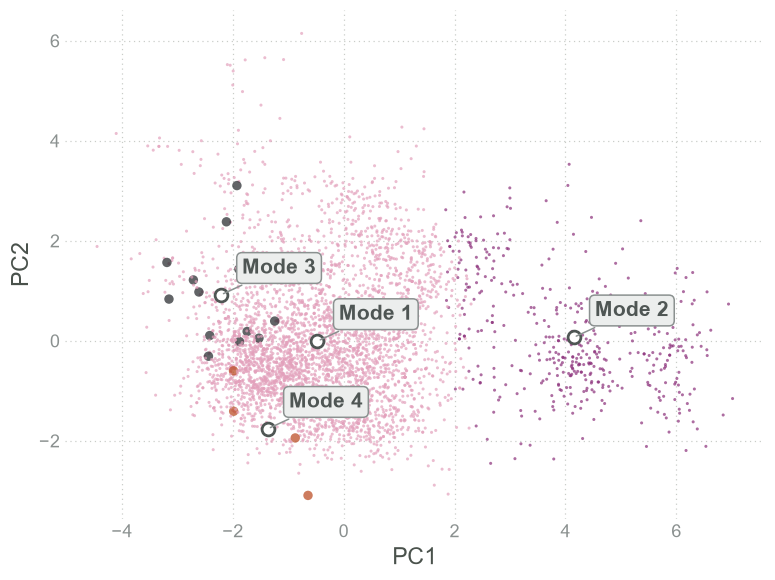

bandwidth 3.16 | modes: {0: 3675, 1: 427, 3: 13, 2: 4}


In [66]:
bw = estimate_bandwidth(Xs, quantile=0.3, random_state=SEED)
lab = MeanShift(bandwidth=bw, bin_seeding=True).fit_predict(Xs)

# Order modes by size, as in the composition table
vc = pd.Series(lab).value_counts()
ctr_9d = {l: Xs[lab == l].mean(axis=0) for l in vc.index}
ctr_pc = {l: pcs[lab == l, :2].mean(axis=0) for l in vc.index}  # projected onto PC1–PC2 for plotting

GREY, GREYTXT = "#8b9190", "#4f5654"
MODE_COLS = ["#e3a1bc", "#8b2f7a", "#1f2327", "#b8451a", "#2a78d6", "#0f7550", "#8a5d00"]
cm = {l: MODE_COLS[i % len(MODE_COLS)] for i, l in enumerate(vc.index)}
major_modes = set(vc.index[:2])

fig, ax = plt.subplots(figsize=(8.2, 6.0))
o = np.random.default_rng(SEED).permutation(len(lab))

ax.scatter(
    pcs[o, 0],
    pcs[o, 1],
    c=[cm[l] for l in lab[o]],
    s=[4 if l in major_modes else 38 for l in lab[o]],
    lw=0,
    alpha=0.7,
    rasterized=True,
)

for i, l in enumerate(vc.index):
    cx, cy = ctr_pc[l]
    ax.scatter([cx], [cy], s=70, marker="o", facecolor="white", edgecolor=GREYTXT, lw=1.8, zorder=5)
    ax.annotate(
        f"Mode {i + 1}",
        (cx, cy),
        xytext=(14, 14),
        textcoords="offset points",
        fontsize=14,
        fontweight="bold",
        color=GREYTXT,
        zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", fc="#eceeed", ec=GREY, lw=1),
        arrowprops=dict(arrowstyle="-", color=GREY, lw=1),
    )

ax.set_xlabel("PC1", fontsize=15, color="#4a524c")
ax.set_ylabel("PC2", fontsize=15, color="#4a524c")
ax.grid(True, ls=(0, (1, 3)), lw=0.8, color="#c9ccc8")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0, labelsize=12, colors="#8b9190")

save(fig, "ms_q02c")
print(f"bandwidth {bw:.2f} | modes: { {int(l): int(v) for l, v in vc.items()} }")
ms = {}
for q in (0.15, 0.2, 0.3):
    bw_q = estimate_bandwidth(Xs, quantile=q, random_state=SEED)
    ms[q] = (bw_q, MeanShift(bandwidth=bw_q, bin_seeding=True).fit_predict(Xs))

bw, lab = ms[0.3]  # or ms[0.2] to match the UMAP panel and markdown

**Reading the figure** · **What it shows.** The 5,874 species on PC1 and PC2, coloured by mean-shift mode; the grey labels mark each mode's centre.

**How to read it.** Mode 1 is the large cloud, mode 2 is the aerial island on the right, mode 3 is six scattered outlier species (its centre falls in empty space).

**Takeaway.** Mean-shift sees one big cloud: 91% of species fall in a single mode. Only the island is a separate peak.

## I.5 · Where the two methods agree: the M1 island
**Question it serves.** The methods disagree on the *number* of groups. Do they at least agree where there is a real gap?
**What this cell does.** For each bandwidth it finds the mean-shift mode holding most M1 species and measures how much of M1 it captures (recall) and how much of the mode is M1 (purity). It then cross-tabulates the modes found at the bandwidth that captures M1 best against the morphotypes.
**Why.** If one mode coincides with M1 while the rest of the cloud merges, then M1 is a real island, and the borders between the other groups are choices.

          modes  mode_size  M1_recall  purity
quantile                                     
0.15         13        337       0.94    0.90
0.20          8        375       0.97    0.83
0.30          4        427       1.00    0.75


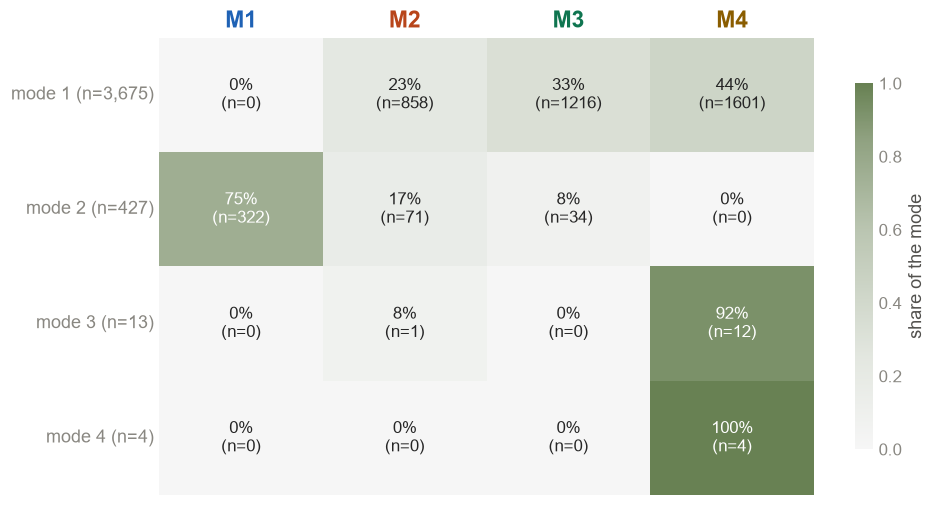

In [67]:
m1 = df.Cluster.to_numpy() == 0
rows = []
for q, (bw, lab) in ms.items():
    top = pd.Series(lab[m1]).value_counts().index[0]
    in_top = lab == top
    rows.append(dict(quantile=q, modes=len(np.unique(lab)), mode_size=int(in_top.sum()),
                     M1_recall=m1[in_top].sum() / m1.sum(), purity=m1[in_top].mean()))
ms_m1 = pd.DataFrame(rows).set_index("quantile")
print(ms_m1.round(2).to_string())

Q_BEST = ms_m1.M1_recall.idxmax()   # the bandwidth whose best mode captures most of M1
tab = pd.crosstab(ms[Q_BEST][1], df.Cluster.map(dict(enumerate(MT))))
tab = tab.loc[tab.sum(1).sort_values(ascending=False).index]
tab.index = [f"mode {i + 1} (n={tab.loc[k].sum():,})" for i, k in enumerate(tab.index)]
pct_ = tab.div(tab.sum(1), axis=0)

fig, ax = plt.subplots(figsize=(9.6, 5.4))
annot = np.array([[f"{pct_.iloc[i, j]:.0%}\n(n={tab.iloc[i, j]})" for j in range(tab.shape[1])] for i in range(tab.shape[0])])
sns.heatmap(pct_, annot=annot, fmt="", cmap=SEQ, vmin=0, vmax=1, ax=ax, linewidths=0, linecolor="none",
            cbar_kws=dict(label="share of the mode", shrink=0.8), annot_kws=dict(fontsize=11))
ax.set_xlabel(""); ax.set_ylabel("")
ax.xaxis.tick_top()
for lbl, col in zip(ax.get_xticklabels(), MT_TXT): lbl.set_color(col); lbl.set_fontweight("bold"); lbl.set_fontsize(15)
for t in ax.get_yticklabels(): t.set_fontsize(12); t.set_rotation(0)
ax.tick_params(length=0)
for s_ in ax.spines.values(): s_.set_visible(False)
cb = ax.collections[0].colorbar; cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=11); cb.set_label("share of the mode", fontsize=12)
save(fig, "ms_heat_p7")

**Reading the figure** · **What it shows.** For each mean-shift mode (rows), the composition by k-means morphotype (columns).

**Takeaway.** The two methods agree in one place only: mode 2 holds all 338 M1 species (it is 68% M1). 91% of all species sit in mode 1. Everywhere else the number of groups is our choice, so M2–M4 are useful slices of a continuum, not natural types.

### Findings · structure
* Nine shape features, one PCA: the first four components carry 76% of the variance.
* k = 4 is the largest k that is stable across random halves of the species (0.92); the silhouette is 0.16 against 0.09 for shuffled data, so the structure is real but weak, as expected for a continuum.
* **Only the aerial island (M1, 338 species) is a separate region.** Mean-shift finds it too and puts 91% of species in one mode.
* M2, M3 and M4 share one cloud: graded types, and four is our choice of cut.

In [ ]:
class MorphBadgeHandler(HandlerBase):
    """Badge arrotondato nella legenda perfettamente allineato al testo."""
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        color, code = orig_handle
        badge_h = height * 0.92
        y_center = ydescent + height * 0.50

        badge = FancyBboxPatch(
            (xdescent, y_center - badge_h / 2.0),
            width,
            badge_h,
            boxstyle="round,pad=0.04,rounding_size=2.5",
            facecolor=color,
            edgecolor="none",
            transform=trans,
        )
        txt = Text(
            xdescent + width / 2.0,
            y_center,
            code,
            color="white",
            fontsize=fontsize * 0.85,
            fontweight="bold",
            ha="center",
            va="center",
            transform=trans,
        )
        return [badge, txt]

# 1. Calcolo proiezione UMAP sulle 9 feature standardizzate (Xs)
reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.15,
    metric="euclidean",
    random_state=SEED,
)
emb_umap = reducer.fit_transform(Xs)

# 2. Recupero etichette Mean-Shift (quantile 0.2, già calcolato in ms[0.2][1])
lab_ms = ms[0.2][1]
vc_ms = pd.Series(lab_ms).value_counts()
mode_pal = ["#e6b8c9", "#c84b7a", "#7a1842", "#f2d5e0"]
cmap_ms = {c: mode_pal[i] if i < len(mode_pal) else "#f5dfe7" for i, c in enumerate(vc_ms.index)}

BIG = {"font.size": 12, "axes.labelsize": 12, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5, "legend.fontsize": 11}
with plt.rc_context(BIG):
    fig, (ax_km, ax_ms) = plt.subplots(1, 2, figsize=(15.5, 6.6))
    o_ = np.random.default_rng(SEED).permutation(len(df))

    # Limiti stretti comuni a entrambi i pannelli (4% di margine)
    xmin, xmax = emb_umap[:, 0].min(), emb_umap[:, 0].max()
    ymin, ymax = emb_umap[:, 1].min(), emb_umap[:, 1].max()
    xpad = (xmax - xmin) * 0.04
    ypad = (ymax - ymin) * 0.04

    # --- PANNELLO SINISTRO: k-Means (k=4) su UMAP ---
    ax_km.scatter(
        emb_umap[o_, 0], emb_umap[o_, 1],
        c=[CL_PAL[c] for c in df.Cluster.values[o_]],
        s=5, lw=0, alpha=0.50, rasterized=True,
    )

    badge_handles = [(CL_PAL[c], MT[c]) for c in range(K)]
    badge_labels = [f"(n={(df.Cluster.values == c).sum():,})" for c in range(K)]
    ax_km.legend(
        handles=badge_handles,
        labels=badge_labels,
        handler_map={tuple: MorphBadgeHandler()},
        loc="upper right",
        frameon=True,
        facecolor="white",
        edgecolor="#dddddd",
        framealpha=0.92,
        handlelength=2.2,
        handleheight=1.45,
        handletextpad=0.6,
        labelspacing=0.55,
        fontsize=11,
    )


    # --- PANNELLO DESTRO: Mean-Shift (quantile 0.2) su UMAP ---
    for c in reversed(vc_ms.index):
        m_ = (lab_ms == c)
        rank = vc_ms.index.get_loc(c)
        is_small = 1 <= rank <= 2
        ax_ms.scatter(
            emb_umap[m_, 0], emb_umap[m_, 1],
            color=cmap_ms[c],
            s=18 if rank == 2 else (7.5 if rank == 1 else 4.5),
            lw=0,
            alpha=0.90 if is_small else 0.55,
            rasterized=True,
        )

    for i, c in enumerate(vc_ms.index[:3]):
        m_ = (lab_ms == c)
        cx, cy = np.median(emb_umap[m_, 0]), np.median(emb_umap[m_, 1])
        ax_ms.text(
            cx, cy, f"Mode{i + 1}",
            fontsize=12, fontweight="bold", color="white",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.26", fc="#4a4a4a", ec="white", lw=1.2),
            zorder=6,
        )

    # Formattazione comune degli assi UMAP1 / UMAP2
    for ax in (ax_km, ax_ms):
        ax.set_xlim(xmin - xpad, xmax + xpad)
        ax.set_ylim(ymin - ypad, ymax + ypad)
        ax.set_xlabel("UMAP1")
        ax.set_ylabel("UMAP2")
        ax.set_aspect("equal", adjustable="box")
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_color("#cccccc")
        ax.spines["bottom"].set_color("#888888")
        ax.grid(True, linestyle="--", alpha=0.25)

    fig.tight_layout(w_pad=2.5)
    save(fig, "04g_umap_kmeans_vs_meanshift")

## I.6 · Anatomy of the four morphotypes (descriptive only)
These differences are guaranteed by construction (these features built the groups), so the figures name the groups; they are not evidence that the groups are real.

In [ ]:
Z=pd.DataFrame(Xs,columns=INTERNAL_MORPH_COLS); cl=df.Cluster.values
feats=list(INTERNAL_MORPH_COLS)
NM={"log_Mass":"Body mass","Rel_Beak_Length":"Relative beak length","Beak_Aspect":"Beak length/width","Beak_Depth_Width":"Beak depth/width","Nares_Beak":"Nares/beak length","Rel_Tarsus":"Relative tarsus (leg)","Rel_Wing":"Relative wing","Tail_Wing":"Tail/wing","log_HWI":"Hand-wing index"}
sizes_=[int((cl==c).sum()) for c in range(K)]
fig,axs=plt.subplots(3,3,figsize=(15,11),gridspec_kw=dict(hspace=0.34,wspace=0.2))
rng_jit=np.random.default_rng(1)
for ax,f in zip(axs.ravel(),feats):
    data=[Z.loc[cl==c,f].values for c in range(K)]
    med=np.array([np.median(v) for v in data])
    gap=[abs(med[c]-np.mean(np.delete(med,c))) for c in range(K)]
    star=int(np.argmax(gap))
    for c,v in enumerate(data):
        a=0.35 if c==star else 0.16
        ax.scatter(c+rng_jit.uniform(-0.3,0.3,len(v)),v,s=3,color=PAL[c],alpha=a,lw=0,rasterized=True,zorder=1)
    bp=ax.boxplot(data,positions=range(K),widths=0.6,notch=True,patch_artist=True,showfliers=False,whis=1.5,zorder=4,
                  medianprops=dict(color="#1f2a24",lw=2),boxprops=dict(lw=1),whiskerprops=dict(lw=1.2),capprops=dict(lw=1.2))
    for c,b_ in enumerate(bp["boxes"]):
        b_.set_facecolor(PAL[c]); b_.set_alpha(0.95 if c==star else 0.35); b_.set_edgecolor(PAL[c] if c==star else "#a8aaa6")
    for c in range(K):
        col="#1f2a24" if c==star else "#8b9190"
        for w in (bp["whiskers"][2*c],bp["whiskers"][2*c+1],bp["caps"][2*c],bp["caps"][2*c+1]): w.set_color(col)
    ax.grid(axis="y",color="#e3e1d8",lw=0.8); ax.set_axisbelow(True); ax.grid(axis="x",visible=False)
    ax.set_xticks(range(K),[f"{MT[c]}"+chr(10)+f"n={sizes_[c]:,}" for c in range(K)])
    for t_,c_ in zip(ax.get_xticklabels(),MT_TXT): t_.set_color(c_); t_.set_fontweight("bold"); t_.set_fontsize(11)
    ax.tick_params(length=0,labelsize=11)
    if ax not in axs[-1]: ax.set_xticklabels([])
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.set_xlim(-0.6,K-0.4)
    allv=np.concatenate(data); ax.set_ylim(np.percentile(allv,0.3)-0.3,np.percentile(allv,99.7)+0.3)
    ax.set_title(f"{NM[f]}",fontsize=13,fontweight=700,color="#1f2a24",loc="left",pad=26)
    for c in range(K):
        ax.text(c,1.04,f"{med[c]:+.1f}",transform=ax.get_xaxis_transform(),ha="center",va="bottom",fontsize=11,
                fontweight=700 if c==star else 400,color=MT_TXT[c] if c==star else "#6b716d")
fig.subplots_adjust(bottom=0.1)
fig.text(0.5,-0.005,"Each dot is a species. Box = quartiles, whiskers = 1.5 × IQR, bar = median, notch = 95% CI of the median. Numbers on top = medians. Each panel has its own scale, in SD from the cohort mean.",ha="center",fontsize=12,color="#4a524c")
save(fig, "box_shape_sm", dpi=130); plt.show()

**Reading the figure** · **What it shows.** One panel per shape feature, in standard deviations from the cohort mean, with every species as a dot. Box = quartiles, whiskers = 1.5 × IQR, bar = median, notch = 95% confidence interval of the median. The morphotype whose median is farthest from the others is drawn in full colour.

**Takeaway.** M1 stands out on seven of nine features (pointed wings, long hand-wing index, short legs, short and flat beaks); M2 is heaviest and M4 has the broadest beak length/width. M2, M3 and M4 overlap on most features.

## I.7 · Median of each feature per morphotype

In [ ]:
z_med = pd.DataFrame(Xs, columns=INTERNAL_MORPH_COLS).groupby(df.Cluster.values).median().T
for c in range(K):
    fams = df.loc[df.Cluster == c, "Family1"].value_counts().head(3).index

fig, a1 = plt.subplots(figsize=(10, 6.6))
lim = np.abs(z_med.values).max()
im1 = a1.imshow(z_med.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
for i, f in enumerate(z_med.index):
    row = z_med.iloc[i].values
    for j in range(K):
        v = row[j]
        txt = f"{v:+.1f}".replace("-0.0", "0.0").replace("+0.0", "0.0")
        extreme = v == row.max() or v == row.min()          # highest and lowest of the row in bold
        a1.text(j, i, txt, ha="center", va="center", fontsize=14, fontweight="bold" if extreme else "normal",
                color="white" if abs(v) > 0.6 * lim else INK)
a1.set_yticks(range(len(z_med)), [NICE[f] for f in z_med.index], fontsize=13)
a1.set_xticks([])
a1.tick_params(length=0)
for s in a1.spines.values(): s.set_visible(False)
a1.grid(False)
for j in range(K):                                           # cluster names on top, in the cluster colour
    a1.text(j, -0.95, MT[j], ha="center", va="center", fontsize=19, fontweight="bold",
            color=["#1f62b5", "#b8451a", "#0f7550", "#8a5d00"][j], clip_on=False)
cb = fig.colorbar(im1, ax=a1, shrink=0.8, pad=0.02, label="SD from the cohort mean")
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=11, length=0)
save(fig, '06_portrait_slide')

**Reading the figure** · **What it shows.** The median of each feature per morphotype, in standard deviations from the cohort mean (green above, slate below); the highest and lowest of each row are in bold.

**Takeaway.** M1 (338): pointed wings, tiny legs, flat wide bill. M2 (1,554): the heaviest, deep bills. M3 (1,962): the smallest, average proportions. M4 (2,020): long legs and tail, rounded wings.

# Chapter II · Function: do the groups hunt differently?
**Last chapter → this chapter:** Chapter I found one aerial island and a continuum cut into four morphotypes from shape alone. **Question:** do they hunt differently, on variables the clustering never saw? The technique shares were not shown to the clustering, so a difference is not guaranteed by construction.

**Plan.** II.1 tests every technique share (Kruskal–Wallis, with two family-level controls). II.2 asks how much of the signal is the aerial island, and tests geography. II.3 describes the groups with a surrogate model on outside variables. II.4 looks inside the continuum: where sallying and gleaning sit, and which pairs differ.

## II.1 · The test engine and the technique shares
**Question it serves.** Do the body plans forage differently, on variables the clustering never saw?
**What this cell does.** It defines the tests used throughout this chapter and runs them on the 5 foraging shares: aerial screening, sally, glean, bark, and fruit & seed.
**How.**
* **Level 1, overall test.** Kruskal–Wallis, with effect size ε² = H / (N − 1) (0.01 small, 0.08 medium, 0.26 large). Benjamini–Hochberg corrects for the 5 tests.
* **Lineage control (family-level test).** One mean per family, grouped by the family's majority morphotype, so a family of 400 species counts once.
* **Level 3, pairwise tests.** Mann–Whitney between all 6 pairs of morphotypes, with Holm correction. A **unique marker** is a morphotype that differs from all three others in the same direction.

**Why a family-level control.** Relatives are not independent data points, so species-level p-values are too optimistic. It asks the question every reviewer will ask: *is this just lineage?* Effect sizes are reported because with 5,874 species even trivial differences are significant. The family-level test is a control we add; the lectures assume independent observations.
**Why no yes/no "aerial screener" test here.** It is only the screening share cut at 50%, so it would repeat the screening-share test. Chapter III predicts the main technique instead.

In [ ]:
def magnitude(e, kind):
    cuts = (0.01, 0.08, 0.26) if kind == "ε²" else (0.1, 0.3, 0.5)
    labels = ("negligible", "small", "medium", "large")
    return labels[np.searchsorted(cuts, e, side="right")]


def level1(data, cont, cat, block):
    rows = []
    cont_set = set(cont)

    for var in cont + cat:
        sub = data[[var, "Cluster"]].dropna()
        v = sub[var].to_numpy()
        lab = sub["Cluster"].to_numpy()

        if var in cont_set:
            H, p = stats.kruskal(*[v[lab == c] for c in range(K)])
            eff, eff_name, stat, min_exp = H / (len(v) - 1), "ε²", H, np.nan
        else:
            vv = v.astype(int).astype(str) if np.issubdtype(v.dtype, np.number) else v.astype(str)
            tab = pd.crosstab(lab, vv)
            small = tab.columns[tab.sum() < 15]
            if len(small):  # lump rare categories so expected counts stay >= 5
                vv = np.where(np.isin(vv, small), "Other", vv)
                tab = pd.crosstab(lab, vv)
            if tab.shape[1] < 2:
                stat, p, eff, eff_name, min_exp = 0.0, 1.0, 0.0, "Cramér's V", np.nan
            else:
                chi2, p, _, exp = stats.chi2_contingency(tab)
                eff = np.sqrt(chi2 / (tab.to_numpy().sum() * (min(tab.shape) - 1)))
                eff_name, stat, min_exp = "Cramér's V", chi2, exp.min()

        rows.append(
            dict(
                block=block,
                variable=var,
                test="Kruskal–Wallis" if var in cont_set else "χ²",
                n=len(v),
                stat=stat,
                effect=eff,
                effect_size=eff_name,
                magnitude=magnitude(eff, eff_name),
                p=p,
                min_expected=min_exp,
            )
        )

    t = pd.DataFrame(rows)
    t["q"] = multipletests(t["p"], method="fdr_bh")[1] if len(t) else []
    print(f"{block}: Benjamini–Hochberg over m = {len(t)} variables")
    return t



**Reading the output** · **Takeaway.** All five foraging shares differ between morphotypes (q < 0.05). Screening is very large (ε² = 0.75), gleaning large (0.33), sallying medium (0.19), bark and fruit/seed small (0.08, 0.04). Bark is the weakest at family level (p = 0.050), so it rests on a few lineages such as woodpeckers. The unique markers match the anatomy: M1 highest screening and lowest gleaning, M3 highest sallying, M4 highest gleaning and lowest sallying, M2 highest bark.

In [ ]:
niche_codes = ["IAE", "ISA", "ISS", "ISG", "IGE", "IGG", "IVS", "Generalist"]
df["MainNiche_grp"] = np.where(df["MainNiche"].isin(niche_codes), df["MainNiche"], "Other")

EXT_LABELS = {
    "I_Screen": "Screening share",
    "I_Sally": "Sally share",
    "I_Glean": "Glean share",
    "I_Bark": "Bark share",
    "Primary.Lifestyle": "Lifestyle",
    "MainNiche_grp": "Main niche",
    "Abs_Latitude": "|Latitude|",
    "Log_Range_Size": "Range size",
    "Migration": "Migration",
    "Habitat.Density": "Habitat density",
}

EXT = pd.concat(
    [
        level1(df, FORAGING_CONT, [], "foraging"),
        level1(df, [], ["Primary.Lifestyle", "MainNiche_grp"], "labels"),
        level1(df, ["Abs_Latitude", "Log_Range_Size"], ["Migration", "Habitat.Density"], "geography"),
    ],
    ignore_index=True,
)

EXT["kind"] = np.where(EXT["effect_size"] == "ε²", "num", "cat")
EXT["effect_size"] = np.where(EXT["kind"] == "num", "ε²", "V")
EXT["variable"] = EXT["variable"].map(lambda c: EXT_LABELS.get(c, NICE.get(c, c)))

print(f"Effect size of each external variable across the {K} morphotypes (all species)")
print(EXT[["block", "variable", "n", "effect_size", "effect", "magnitude", "q"]].round(3).to_string(index=False))

In [ ]:
MIX = [
    ("I_Screen", "Screening", "#5b3d9e", "#7e57c2"),
    ("I_Sally", "Sally", "#0b8294", "#12a1b8"),
    ("I_Glean", "Glean", "#6a7a10", "#8a9a1a"),
    ("I_Bark", "Bark", "#8a4a14", "#a65f1f"),
]
SERIF_FONT = ["EB Garamond", "Georgia", "DejaVu Serif"]


def fade(color, alpha):
    rgb = np.array(to_rgb(color))
    return tuple(1 - alpha * (1 - rgb))


def style_panel(ax, title, title_col, bar_col):
    ax.set_xlim(-3, 103)
    ax.set_xticks([0, 50, 100])
    ax.set_xticklabels(["0", "50", "100%"], fontsize=12, color="#8a908b")
    ax.grid(False)
    ax.tick_params(length=0)
    ax.set_title(title, fontsize=22, fontweight="600", color=title_col, family=SERIF_FONT, pad=14)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.axvline(0, color=bar_col, lw=3.5, zorder=0.5, solid_capstyle="butt")


yy = np.arange(K)[::-1]
cl = df["Cluster"].to_numpy()
rng_ = np.random.default_rng(1)

fig, axes = plt.subplots(1, len(MIX), figsize=(11.5, 6.0), sharey=True, gridspec_kw=dict(wspace=0.12))

for ax, (col, name, title_col, bar_col) in zip(axes, MIX):
    valid = df[col].notna().to_numpy()
    y_vals = df.loc[valid, col].to_numpy()
    cl_v = cl[valid]
    data = [y_vals[cl_v == k_] for k_ in range(K)]

    vp = ax.violinplot(
        data,
        positions=yy,
        vert=False,
        widths=0.85,
        showextrema=False,
        showmedians=False,
        bw_method=0.15,
    )
    for k_, body in enumerate(vp["bodies"]):
        body.set_facecolor(fade(PAL[k_], 0.6))
        body.set_edgecolor("none")
        body.set_alpha(1)

    for k_, (y_, d) in enumerate(zip(yy, data)):
        q1_, q3_ = np.percentile(d, [25, 75])
        ax.plot([q1_, q3_], [y_, y_], color=MT_TXT[k_], lw=7, solid_capstyle="butt", alpha=0.85, zorder=3)

        boot_meds = np.median(rng_.choice(d, size=(2000, len(d)), replace=True), axis=1)
        lo_, hi_ = np.percentile(boot_meds, [2.5, 97.5])
        ax.plot([lo_, hi_], [y_, y_], color="white", lw=2.2, solid_capstyle="butt", zorder=3.5)
        for edge in (lo_, hi_):
            ax.plot([edge, edge], [y_ - 0.09, y_ + 0.09], color=MT_TXT[k_], lw=2.2, zorder=3.6)

        ax.plot([np.median(d)], [y_], marker="o", ms=7, mfc="white", mec=MT_TXT[k_], mew=1.5, zorder=4)

    style_panel(ax, name, title_col, bar_col)

axes[0].set_yticks(yy, MT)
for tick_lbl, col in zip(axes[0].get_yticklabels(), MT_TXT[:K]):
    tick_lbl.set_color(col)
    tick_lbl.set_fontweight("bold")
    tick_lbl.set_fontsize(24)

save(fig, "mix_violin_ci2")

**Reading the figure** · **What it shows.** For each technique (column) and morphotype (row), the distribution of the share of foraging effort. The thick bar is the interquartile range, the white segment with end ticks the 95% bootstrap confidence interval of the median, the dot the median. The coloured line at 0 is the technique's own colour.

**How to read it.** Shares pile up at exactly 0 and 100, so the tests use ranks and effect sizes, not means.

**Takeaway.** Every share differs between the groups (q < 0.05, Kruskal–Wallis): ε² = 0.75 for screening and 0.33 for glean (large), 0.19 for sally (medium), 0.08 for bark and 0.04 for fruit/seed (small). M1 spends 79% of its foraging screening the air; M4 spends 78% gleaning; M3 splits between sallying (38%) and gleaning (45%); M2 mixes everything and holds almost all the bark foraging.

## II.4 · Inside the continuum: where sallying and gleaning sit
**Question it serves.** Without M1, sallying and gleaning keep medium-to-large effects. Where in the continuum do they sit, and which groups differ?
**What this cell does.** Two figures.
1. **Maps.** The PCA map coloured by sally, glean, bark and screening share. Single species are noisy (many shares are exactly 0 or 100), so each point shows the mean share of its 30 nearest neighbours **in the 9-feature space** (not in the map): a smoothed trend, no model involved.
2. **Pairwise follow-up** (lecture 6b: global → pairwise). Every pair of morphotypes is compared on each technique with Mann–Whitney, Holm-corrected within the technique. The effect size is the **rank-biserial correlation** r = P(row > column) − P(row < column), from −1 to +1 (0.15 small, 0.33 medium, 0.47 large). The Holm-adjusted p says whether a difference is distinguishable from chance, r says how large it is; with groups of thousands almost every p is tiny, so r is what separates large from negligible. These p-values are species-level and optimistic. The choice to look closely at sally and glean follows the global results, and is reported as such.

In [68]:
TF = dict(fontfamily=["EB Garamond", "Georgia", "DejaVu Serif"], fontsize=24, fontweight=600, loc="left")


def prep_contours(E, cl, mass=0.85, bw=0.3, min_island_ratio=0.25):
    """Compute plot bounds, cluster medians, and smooth KDE contours enclosing `mass` of each cluster."""
    lo, hi = np.percentile(E, [0.25, 99.75], axis=0)
    pad = 0.06 * (hi - lo)
    bounds = (lo[0] - pad[0], hi[0] + pad[0], lo[1] - pad[1], hi[1] + pad[1])

    x_grid = np.linspace(bounds[0], bounds[1], 240)
    y_grid = np.linspace(bounds[2], bounds[3], 200)
    gx, gy = np.meshgrid(x_grid, y_grid)
    grid_pts = np.vstack([gx.ravel(), gy.ravel()])

    contours, medians = {}, {}
    for c in range(K):
        P = E[cl == c]
        medians[c] = np.median(P, axis=0)
        kde = gaussian_kde(P.T, bw_method=bw)
        z = kde(grid_pts).reshape(gx.shape)
        lines = find_contours(z, np.quantile(kde(P.T), 1 - mass))
        if lines:
            max_len = max(len(line) for line in lines)
            contours[c] = [
                (
                    np.interp(line[:, 1], np.arange(len(x_grid)), x_grid),
                    np.interp(line[:, 0], np.arange(len(y_grid)), y_grid),
                )
                for line in lines
                if len(line) >= min_island_ratio * max_len
            ]
        else:
            contours[c] = []

    return bounds, contours, medians


def draw_embedding_overlay(ax, bounds, contours, medians, is_umap=False):
    """Overlay dashed morphotype contours, median badges, and standard 2D embedding styling."""
    for c in range(K):
        for xs_, ys_ in contours[c]:
            ax.plot(xs_, ys_, color=CL_PAL[c], lw=1.5, ls=(0, (4, 3)), zorder=6)
        ax.text(
            *medians[c],
            MT[c],
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=CL_PAL[c],
            zorder=8,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75),
        )
    ax.set_xlim(bounds[0], bounds[1])
    ax.set_ylim(bounds[2], bounds[3])
    for spine in ("left", "bottom"):
        ax.spines[spine].set_visible(False)

    if is_umap:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    else:
        ax.grid(True)
        ax.tick_params(length=0)


def plot_technique_grid(E, map_name, xl, yl, smooth_dict, bw=0.3, is_umap=False):
    """Plot the 2x2 foraging-share map on any 2D embedding (PCA or UMAP)."""
    bounds, contours, medians = prep_contours(E, df["Cluster"].to_numpy(), bw=bw)

    with plt.rc_context({"grid.linestyle": ":", "grid.linewidth": 0.7, "grid.color": "#cfcdc4", "grid.alpha": 0.6}):
        fig, axes = plt.subplots(2, 2, figsize=(12.5, 9), sharex=True, sharey=True)

        for ax, (col, lab, tc) in zip(axes.ravel(), TECHNIQUES):
            v = smooth_dict[col]
            oo = np.argsort(v, kind="stable")
            sc = ax.scatter(
                E[oo, 0], E[oo, 1], c=v[oo], cmap=SEQ, vmin=0, vmax=100, s=5, lw=0, alpha=0.9, rasterized=True
            )
            draw_embedding_overlay(ax, bounds, contours, medians, is_umap=is_umap)
            ax.set_title(lab, color=tc, **TF)

        for ax in axes[1]:
            ax.set_xlabel(xl)
        for ax in axes[:, 0]:
            ax.set_ylabel(yl)

        cb = fig.colorbar(sc, ax=axes, fraction=0.025, pad=0.02, shrink=0.7)
        cb.set_label("% of foraging effort (30 nearest species in shape)", color=INK2)
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=0)

        suptitle(
            fig,
            "One aerial island, then sallying gives way to gleaning across the rest of body-shape space",
            f"{map_name} · dashed lines enclose 85% of each morphotype · foraging shares were never used to build "
            "the maps or the clusters",
            y=1.0,
        )
        save(fig, f"06e_maps_techniques_{map_name.lower()}")

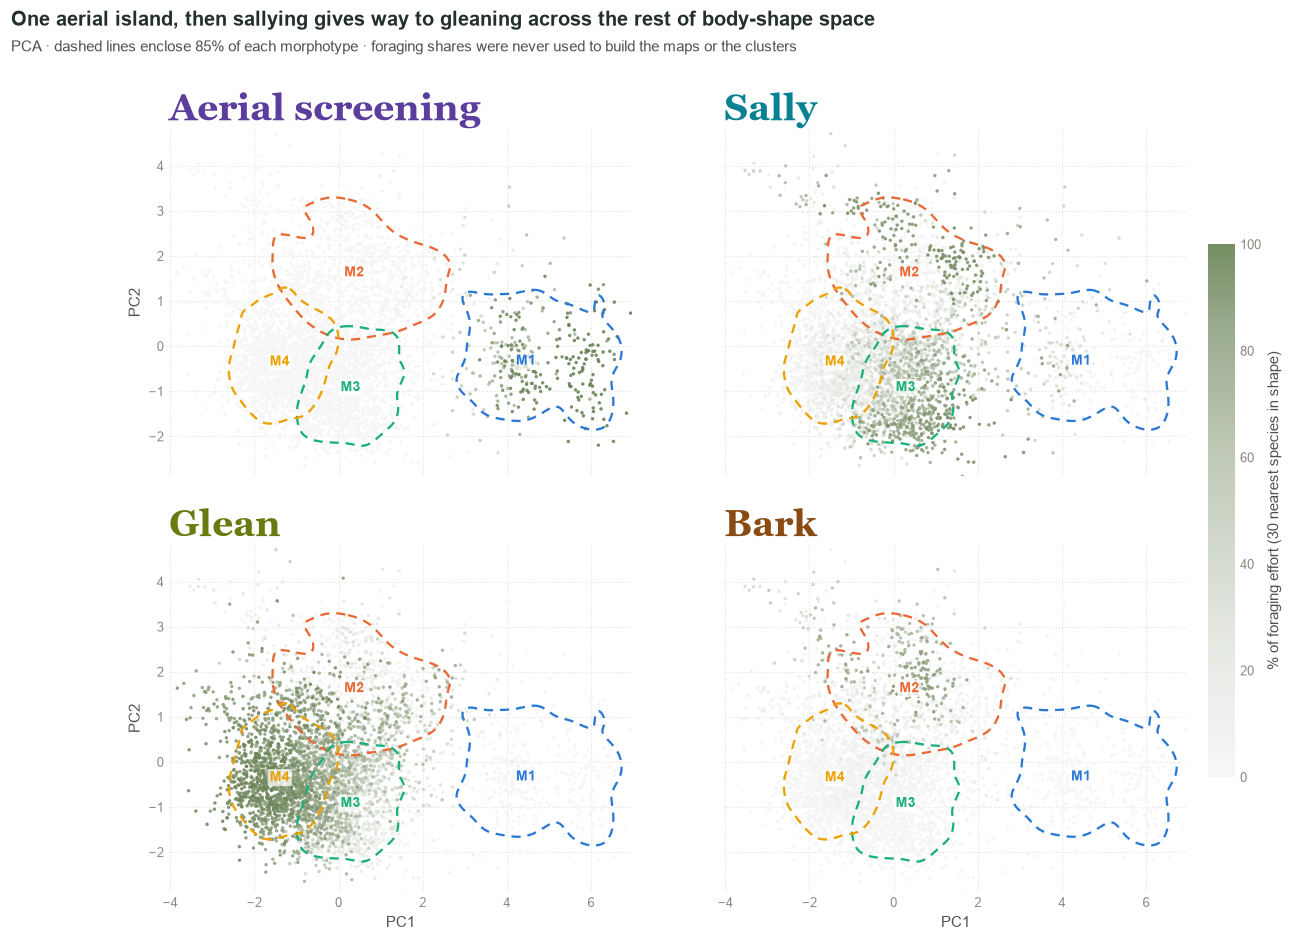

In [69]:
nbr = NearestNeighbors(n_neighbors=30).fit(Xs).kneighbors(Xs, return_distance=False)
smooth = {col: np.nanmean(df[col].to_numpy()[nbr], axis=1) for col, _, _ in TECHNIQUES}

plot_technique_grid(pcs[:, :2], "PCA", "PC1", "PC2", smooth, bw=0.3)

In [ ]:
if "emb_umap" not in globals():
    emb_umap = umap.UMAP(random_state=SEED).fit_transform(Xs)

plot_technique_grid(emb_umap, "UMAP", "UMAP 1", "UMAP 2", smooth, bw=0.22, is_umap=True)

**Reading the figure** · **What it shows.** The PCA map once per technique. Colour: the mean share of the 30 nearest species in shape space; dashed lines enclose 85% of each morphotype.

**Takeaway.** Screening exists only in M1. Sallying peaks in M3 and in part of M2, gleaning in M4, and bark is rare with a pocket in M2. Colours change smoothly with no breaks: a gradient, not separate groups. The morphotypes are slices of it.

In [ ]:
TECHNIQUES = [
    ("I_Screen", "Aerial screening", "#5b3d9e"),
    ("I_Sally", "Sally", "#0b8294"),
    ("I_Glean", "Glean", "#6a7a10"),
    ("I_Bark", "Bark", "#8a4a14"),
]
PAIRS = list(combinations(range(K), 2))
TF = dict(fontfamily=["EB Garamond", "Georgia", "DejaVu Serif"], fontsize=24, fontweight=600)


def rank_biserial(a, b):
    u_stat, p_val = stats.mannwhitneyu(a, b)
    return 2 * u_stat / (len(a) * len(b)) - 1, p_val


cl = df["Cluster"].to_numpy()
PW = {}
for col, _, _ in TECHNIQUES:
    valid = df[col].notna().to_numpy()
    y = df.loc[valid, col].to_numpy()
    cl_v = cl[valid]

    out = [rank_biserial(y[cl_v == j], y[cl_v == i]) for i, j in PAIRS]
    res = pd.DataFrame(
        dict(
            i=[i for i, _ in PAIRS],
            j=[j for _, j in PAIRS],
            r=[r_val for r_val, _ in out],
            q=multipletests([p_val for _, p_val in out], method="holm")[1],
        )
    )
    res["holds"] = (res["q"] < 0.05) & (res["r"].abs() >= 0.33)
    PW[col] = res

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.4), gridspec_kw=dict(wspace=0.12, hspace=0.5))

for ax, (col, lab, title_col) in zip(axes.ravel(), TECHNIQUES):
    t = PW[col]
    M = np.full((K, K), np.nan)
    for row in t.itertuples():
        M[row.j, row.i] = row.r
        ax.text(
            row.i,
            row.j,
            f"{row.r:+.2f}",
            ha="center",
            va="center",
            fontsize=21,
            color="white" if abs(row.r) > 0.45 else INK,
            fontweight="bold" if row.holds else "normal",
        )
        if row.q >= 0.05:
            ax.text(row.i, row.j + 0.3, "n.s.", ha="center", va="center", fontsize=14, color=INK2)

    im = ax.imshow(np.ma.masked_invalid(M), cmap=DIV, vmin=-0.8, vmax=0.8)
    means = df.groupby("Cluster")[col].mean()
    ticks = [f"{MT[c]}\n{means[c]:.0f}%" for c in range(K)]

    ax.set_xticks(range(K), ticks)
    ax.set_yticks(range(K), ticks)
    ax.set_xlim(-0.5, K - 1.5)
    ax.set_ylim(K - 0.5, 0.5)
    ax.set_title(lab, loc="left", color=title_col, **TF)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0, labelsize=17)

cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, shrink=0.8)
cb.set_label("effect size r (rank-biserial)", fontsize=14, color=INK2)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=13, length=0)

save(fig, "pairwise_slide4c")

**Reading the figure** · **What it shows.** Every pair of morphotypes on each technique: the rank-biserial r (row against column). Bold = at least medium effect. All pairs have Holm-adjusted p < 0.001 except two marked n.s.

**Takeaway.** M3 sallies far more than M4 (r = 0.56); M4 gleans more than M2 (0.66) and M3 (0.53). M2 and M3 differ little on both; M2 is set apart by bark.

### Findings · Chapter II
* All technique shares differ between morphotypes (q < 0.05): screening ε² = 0.75 and gleaning 0.33 (large), sallying 0.19 (medium), bark 0.08 and fruit/seed 0.04 (small).
* **The island is aerial screening.** Without M1, screening falls from ε² = 0.75 to 0.02.
* **The continuum is a technique gradient.** Without M1, sallying does not shrink (0.19 → 0.20) and gleaning stays large (0.33 → 0.26).
* **Inside the continuum** M3 sallies far more than M4 (r = 0.56) and M4 gleans more than M2 and M3 (r = 0.66, 0.53); M2 is set apart by bark.
* **Described from external variables only**, a surrogate recovers the morphotype on unseen families (balanced accuracy 0.61, chance 0.25). Odds ratios against M3: M4 sallies far less (×0.19 per SD) and rarely migrates; M2 more bark (×1.8); M1 less sallying and fruit.
* **Geography adds little**: |latitude| 0.004; migration fails the family test.

# Chapter III · Stress test: does shape predict the technique on lineages never seen?
**Last chapter → this chapter:** Chapter II showed that the morphotypes hunt differently, but groups are our own construction, and averages can hide a lot. **Question:** can the *raw features* predict a bird's hunting technique, with no clusters involved, for families (and orders) the model never trained on? **Why it matters:** a rule that only works on relatives of the training birds would be ancestry in disguise; a rule that transfers to new lineages is evidence of convergence, the same body–function link evolving again and again. We predict each bird's **main technique** (aerial screening, sally, glean or bark), find out which traits the prediction needs, and finally check the rule *inside* families.

## III.1 · Predicting the main technique: models, folds and the leakage test
**Question it serves.** Can the 9 raw shape features, with no clusters involved, predict how a bird forages in **families the model has never seen**?
**The target.** The **main technique** of a species is the largest of its four technique shares (aerial screening, sally, glean, bark). Every species gets exactly one label, so this is a four-class problem and the labels cover all 5,874 species. It is *not* a "more than 50%" rule: a bird that forages 45% gleaning, 35% sallying, 15% bark and 5% screening is a gleaner. Many birds are mixtures, so the label is a simplification.
**What this cell does.**
- **Two models.** A multinomial logistic regression (standardised features, class weights balanced) draws linear boundaries. A random forest (400 trees, at least 3 species per leaf, balanced subsample) can draw thresholds and interactions.
- **Two ways of splitting the data.** *Naive* folds (`StratifiedKFold`) put relatives on both sides of the split. *Family* folds (`StratifiedGroupKFold`) hold out whole families.
- 5 folds × 3 repeats. Out-of-fold class probabilities (repeat 1) are stored for later.
- **A shuffled-label baseline.** The same models with the labels randomly permuted, to show what "no signal" scores.

**Metrics.** Each class is scored **one against the rest** from the model's probabilities: *ROC-AUC* (does a bird of this class get a higher score than a bird of another class? 0.5 = chance) and *PR-AUC* (focused on the rarer classes; the no-skill value is the class's share of species). The *macro* average counts the four classes equally. **Macro-F1** and balanced accuracy use the predicted label (the class with the highest probability): F1 balances, for each class, how often a prediction of that class is right against how many true members were found, and macro-F1 averages the four classes equally, so small classes weigh as much as large ones. The chance level is measured with shuffled labels.
**Why two models and two splits.** If the flexible forest beats the linear rule only under naive folds, its extra skill is memorising lineages, not learning body–function rules. The gap between naive and family folds **measures** that leak. Class weights stop the models from ignoring the rarer techniques (gleaning is 64% of species, screening 5%).

In [ ]:
STRAT_COLS = ["I_Screen", "I_Sally", "I_Glean", "I_Bark"]
STRAT_LAB = ["Screening", "Sally", "Glean", "Bark"]
CLS_COL = [PAL[0], PAL[2], PAL[3], PAL[1]]  # morphotype colors: M1 blue, M3 green, M4 gold, M2 orange

assert df[STRAT_COLS].notna().all().all(), "Missing values in STRAT_COLS would corrupt argmax labels"
y4 = df[STRAT_COLS].to_numpy().argmax(axis=1)  # dominant technique per species
counts4 = np.bincount(y4, minlength=len(STRAT_COLS))
prev4 = counts4 / len(y4)
print("Main technique counts:", dict(zip(STRAT_LAB, counts4)), "| shares:", dict(zip(STRAT_LAB, prev4.round(3))))

MODELS = {
    "Logistic regression": lambda s: make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)
    ),
    "Random forest": lambda s: RandomForestClassifier(
        400, min_samples_leaf=3, class_weight="balanced_subsample", random_state=s, n_jobs=-1
    ),
}
M_COL = {"Logistic regression": OCHRE, "Random forest": FOREST}
SCHEMES = {
    "naive (StratifiedKFold)": lambda s: StratifiedKFold(5, shuffle=True, random_state=s),
    "by family (StratifiedGroupKFold)": lambda s: StratifiedGroupKFold(5, shuffle=True, random_state=s),
}
SN, SF = list(SCHEMES)
HEAD = ["macro_roc", "macro_pr"]


def metrics4(y, P):
    """Macro and per-class ROC/PR AUC from class probabilities P (rows = species, cols = 4 techniques)."""
    out, rocs, prs = {}, [], []
    for c, lab in enumerate(STRAT_LAB):
        y_bin = y == c
        ok = 0 < y_bin.sum() < len(y)
        roc = roc_auc_score(y_bin, P[:, c]) if ok else np.nan
        pr = average_precision_score(y_bin, P[:, c]) if ok else np.nan
        out[f"roc_{lab}"], out[f"pr_{lab}"] = roc, pr
        rocs.append(roc)
        prs.append(pr)
    out["macro_roc"] = np.nanmean(rocs)
    out["macro_pr"] = np.nanmean(prs)
    return out


def eval_oof(make_model, splitter, X, y, groups, seed, record_folds=False):
    """Fit 5-fold CV and return pooled OOF probabilities plus optional fold metrics."""
    P = np.zeros((len(y), len(STRAT_COLS)))
    fold_rows = []
    for f_, (tr, te) in enumerate(splitter(seed).split(X, y, groups)):
        mdl = make_model(seed).fit(X[tr], y[tr])
        P[np.ix_(te, mdl.classes_)] = mdl.predict_proba(X[te])
        if record_folds:
            fold_rows.append(dict(rep=seed, fold=f_, **metrics4(y[te], P[te])))
    return P, fold_rows


cv_rows, OOF = [], {}
for sname, splitter in SCHEMES.items():
    for mname, make in MODELS.items():
        for rep in range(3):
            P, folds = eval_oof(make, splitter, XF, y4, groups, seed=rep, record_folds=True)
            cv_rows.extend(dict(scheme=sname, model=mname, **r) for r in folds)
            if rep == 0:
                OOF[(sname, mname)] = P

cv = pd.DataFrame(cv_rows)
print(cv.groupby(["model", "scheme"])[HEAD].agg(["mean", "std"]).round(3).to_string())

scheme_means = cv.groupby(["model", "scheme"])[HEAD].mean().unstack("scheme")
gap = pd.DataFrame({f"{c} gap (naive − family)": scheme_means[(c, SN)] - scheme_means[(c, SF)] for c in HEAD})
print(gap.round(3).to_string())
    # Shuffled-label baseline: same models and family folds, labels randomly permuted (pooled out-of-fold scores)
rng_null = np.random.default_rng(SEED)
null_rows = []
for mname, make in MODELS.items():
    for b in range(3):
        ysh = rng_null.permutation(y4)
        P_null, _ = eval_oof(make, SCHEMES[SF], XF, ysh, groups, seed=b)
        null_rows.append(dict(model=mname, **metrics4(ysh, P_null)))

null = pd.DataFrame(null_rows).groupby("model").mean(numeric_only=True)
print("\nShuffled-label baseline (pooled out-of-fold):")
print(null[HEAD].round(3).to_string())

In [ ]:
mean_ = cv.groupby(["model", "scheme"]).mean(numeric_only=True)
sd_ = cv.groupby(["model", "scheme"]).std(numeric_only=True)
SHORT = {"Logistic regression": "LR", "Random forest": "RF"}


def dumbbell(ax, rows):
    """rows: dicts(label, color, fam, sd, naive, chance) or None for a gap. Filled = unseen families, open = naive."""
    yy, ticks, labs = 0.0, [], []
    for r in rows:
        if r is None:
            yy += 0.6
            continue
        ax.plot([r["fam"], r["naive"]], [yy, yy], color=r["color"], lw=2, alpha=0.5)
        ax.errorbar(r["fam"], yy, xerr=r["sd"], fmt="o", color=r["color"], ms=7, capsize=2)
        ax.scatter(r["naive"], yy, s=50, facecolor="white", edgecolor=r["color"], lw=1.6, zorder=3)
        if r.get("chance") is not None:
            ax.plot([r["chance"]] * 2, [yy - 0.35, yy + 0.35], color=MUTED, lw=1.6, zorder=1)
        ax.text(1.02, yy, f"{r['fam']:.2f} → {r['naive']:.2f}", va="center", fontsize=8, color=INK2,
                transform=ax.get_yaxis_transform())
        ticks.append(yy)
        labs.append(r["label"])
        yy += 1
    ax.set_yticks(ticks)
    ax.set_yticklabels(labs)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)

#### Technique by technique

In [ ]:
PERCLS = pd.DataFrame({(m, s, met): [mean_.loc[(m, s), f"{met}_{l}"] for l in STRAT_LAB]
                       for m in MODELS for s in SCHEMES for met in ("roc", "pr")}, index=STRAT_LAB)
print(PERCLS.xs(SF, axis=1, level=1).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.9), gridspec_kw={"wspace": 0.45})
for ax, (met, mlab) in zip(axes, [("roc", "ROC-AUC"), ("pr", "PR-AUC")]):
    rows = []
    for c, lab in enumerate(STRAT_LAB):
        for mname in MODELS:
            rows.append(dict(label=f"{lab} · {SHORT[mname]}", color=M_COL[mname], fam=mean_.loc[(mname, SF), f"{met}_{lab}"],
                             sd=sd_.loc[(mname, SF), f"{met}_{lab}"], naive=mean_.loc[(mname, SN), f"{met}_{lab}"],
                             chance=0.5 if met == "roc" else prev4[c]))
        rows.append(None)
    dumbbell(ax, rows[:-1])
    ax.set_xlim(0, 1.0)
    ax.set_xlabel(f"{mlab} of the technique against the other three")
    ax.set_title(f"{'A' if met == 'roc' else 'B'}. {mlab} by technique (grey tick = {'chance 0.5' if met == 'roc' else 'no skill = class share'})",
                 fontsize=10)
    ax.text(1.02, -0.9, "family → naive", fontsize=7.5, color=MUTED, transform=ax.get_yaxis_transform())
air_r = mean_.loc[("Logistic regression", SF), "roc_Screening"]
bark_r = mean_.loc[("Random forest", SF), "roc_Bark"]
bark_pr = [mean_.loc[(m, SF), "pr_Bark"] for m in MODELS]
suptitle(fig, f"Aerial screening is found best (ROC-AUC {air_r:.2f} linear, {mean_.loc[('Random forest', SF), 'roc_Screening']:.2f} forest); bark ranks "
         f"decently (ROC-AUC {bark_r:.2f}) but is hard to pick out (PR-AUC {min(bark_pr):.2f}–{max(bark_pr):.2f} vs no skill {prev4[3]:.2f})", "each technique against the other three · unseen families (filled ± SD) and naive folds (open)", y=1.04)
save(fig, "08a1_per_strategy")

**Reading the figure** · **What it shows.** The same prediction, technique by technique: how well the body separates each technique from all the others.

**How to read it.** Dot = score on unseen families (± SD), open dot = naive folds, grey tick = no skill (ROC-AUC 0.5; for PR-AUC the technique's share of species, so rarer techniques start lower).

**Takeaway.** Aerial screening is found almost perfectly (ROC-AUC 0.996 LR, 0.994 RF; PR-AUC 0.86 and 0.82 against a no-skill 0.05). Gleaning ranks well (0.85, 0.87; PR-AUC 0.90–0.91 against 0.64). Sallying is the hardest of the common techniques (0.75 LR, 0.82 RF; PR-AUC 0.57–0.60 against 0.24): many salliers also glean, so the line between them is blurred. Bark is ranked about as well as gleaning (0.82, 0.80) but is hard to pick out: PR-AUC is only 0.25 (LR) and 0.22 (RF), against a no-skill 0.07.

In [ ]:
# Small multiples: one panel per technique, the other three kept in grey as a reference (unseen families, out-of-fold)
TECH_COL = {"Screening": "#5b3fa0", "Sally": "#0b8294", "Glean": "#5c7a1e", "Bark": "#8a4a12"}
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True, gridspec_kw={"hspace": 0.32, "wspace": 0.12})
for row, kind in enumerate(["ROC", "Precision–recall"]):
    for col, focus in enumerate(range(4)):
        ax = axes[row, col]
        col_focus = TECH_COL[STRAT_LAB[focus]]
        for pass_ in ("others", "focus"):
            for c in range(4):
                if (c == focus) != (pass_ == "focus"):
                    continue
                for mname, ls in [("Logistic regression", "-"), ("Random forest", "--")]:
                    P = OOF[(SF, mname)]
                    if kind == "ROC":
                        x_, y_, _ = roc_curve(y4 == c, P[:, c])
                    else:
                        y_, x_, _ = precision_recall_curve(y4 == c, P[:, c])
                    ax.plot(x_, y_, ls=ls, color=col_focus if c == focus else OTHER,
                            lw=2.3 if c == focus else 1.1, alpha=1 if c == focus else 0.45,
                            zorder=3 if c == focus else 1)
        if kind == "ROC":
            ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls=":", zorder=0)
            if col == 0:
                ax.text(0.55, 0.45, "chance", fontsize=9, color=MUTED, rotation=38)
                ax.text(0.04, 0.63, "the other three\ntechniques", fontsize=9, color=MUTED)
            met = "roc"
        else:
            ax.axhline(prev4[focus], color=col_focus, lw=1, ls=":", zorder=2)
            met = "pr"
        sc = {SHORT[m]: mean_.loc[(m, SF), f"{met}_{STRAT_LAB[focus]}"] for m in MODELS}
        title = f"LR {sc['LR']:.2f} · RF {sc['RF']:.2f}"
        if row == 0:
            ax.set_title(f"{STRAT_LAB[focus]}   {title}", fontsize=12, color=col_focus, fontweight="bold", loc="left")
        else:
            ax.set_title(title, fontsize=11, color=col_focus, loc="left")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        if col == 0:
            ax.set_ylabel("ROC · true-positive rate" if kind == "ROC" else "Precision–recall · precision")
        ax.set_xlabel("false-positive rate" if kind == "ROC" else "recall")
axes[0, 1].text(0.30, 0.90, "RF", fontsize=10, color=TECH_COL["Sally"], fontweight="bold")
axes[0, 1].text(0.55, 0.42, "LR", fontsize=10, color=TECH_COL["Sally"], fontweight="bold")
axes[1, 0].text(0.55, 0.45, "precise up to\n~80% recall", fontsize=10, color=TECH_COL["Screening"], fontweight="bold")
axes[1, 3].text(0.3, 0.55, "low precision;\nat best 1 pick in 3\nis really bark", fontsize=10, color=TECH_COL["Bark"], fontweight="bold")
fig.suptitle("Each technique against the rest, on unseen families", fontsize=13, y=1.0)
fig.subplots_adjust(top=0.88, bottom=0.08)
save(fig, "08a3_small_multiples")

**Reading the figure** · **What it shows.** The same out-of-fold predictions on unseen families as the previous figure, one technique per column; the three other techniques stay in grey as a reference.

**How to read it.** Top row: ROC (a curve toward the top-left corner is better, the dotted diagonal is chance). Bottom row: precision–recall (higher is better, the dotted horizontal line is the class share, the score of a model with no skill). Solid = logistic regression, dashed = random forest.

**Takeaway.** Aerial screening hugs the top-left corner and stays high in precision–recall. Gleaning sits well above chance in both rows. Sallying is weaker, and the forest beats the linear model on it. Bark has a decent ROC curve but its precision–recall curve stays near the no-skill line: it ranks birds reasonably but cannot pick out the few bark foragers cleanly.

#### Which techniques get confused?
**What this cell does.** It turns the out-of-fold probabilities into a predicted technique (the most probable class) and draws a confusion matrix for each model, with each row as the share of the true class.
**Why.** The matrix shows where the macro-F1 loses points: which techniques the body tells apart and which it mixes up.

In [ ]:
n_cls = len(STRAT_LAB)
cv_means = cv.groupby(["model", "scheme"])[HEAD].mean()

CM = {m: confusion_matrix(y4, OOF[(SF, m)].argmax(axis=1)) for m in MODELS}
PCT = {m: c / c.sum(axis=1, keepdims=True) for m, c in CM.items()}
rec = {m: np.diag(pct) for m, pct in PCT.items()}
acc = {m: np.trace(c) / len(y4) for m, c in CM.items()}

fig, axes = plt.subplots(1, len(MODELS), figsize=(13, 4.9), gridspec_kw={"wspace": 0.35})

for panel, ax, mname in zip(["A", "B"], axes, MODELS):
    c, pct = CM[mname], PCT[mname]
    annot = np.array([[f"{pct[i, j]:.0%}\n(n={c[i, j]})" for j in range(n_cls)] for i in range(n_cls)])

    sns.heatmap(
        pct,
        annot=annot,
        fmt="",
        cmap=SEQ,
        vmin=0,
        vmax=1,
        ax=ax,
        cbar=True,
        cbar_kws=dict(shrink=0.85, label="share of the true class", format=PercentFormatter(1.0)),
        linewidths=1.5,
        linecolor="white",
        annot_kws=dict(fontsize=8),
    )
    ax.set_xticklabels(STRAT_LAB, rotation=0)
    ax.set_yticklabels([f"{s} ({c[i].sum():,})" for i, s in enumerate(STRAT_LAB)], rotation=0)
    ax.set_xlabel("predicted main technique")
    ax.set_ylabel("true main technique")

    roc_m = cv_means.loc[(mname, SF), "macro_roc"]
    pr_m = cv_means.loc[(mname, SF), "macro_pr"]
    ax.set_title(
        f"{panel}. {mname}: row = share of true class\n"
        f"macro ROC-AUC {roc_m:.2f} · PR-AUC {pr_m:.2f} · macro recall {rec[mname].mean():.0%}",
        fontsize=10,
    )

print("Per-class recall:", {m: dict(zip(STRAT_LAB, r.round(2))) for m, r in rec.items()})

suptitle(
    fig,
    f"The most probable technique is right for {acc['Logistic regression']:.0%} (linear) and "
    f"{acc['Random forest']:.0%} (forest) of species on unseen families; the errors are not spread evenly",
    f"out-of-fold predictions, family-grouped folds (repeat 1) · n = {len(y4):,} species",
    y=1.06,
)
save(fig, "08e_confusion_matrices")

**Reading the figure** · **What it shows.** For each true technique (rows), which technique the model picks (columns), on families never seen in training.

**How to read it.** Each row sums to 100% of the true class. The diagonal is the share found; everything else is a confusion. The title gives macro-F1 and the same score with shuffled labels.

**Takeaway.** Both models find almost every aerial screener (88% LR, 90% RF). The linear model finds 55% of salliers, 73% of gleaners and 65% of bark foragers; the forest 54%, 89% and only 8%. Sallying and gleaning are mixed up in both directions (25–42% of salliers called gleaners, 9–16% of gleaners called salliers), as expected for two ends of a continuum. The forest files most bark species under gleaning (62%), the largest class. Macro-F1 is 0.59 and 0.57, against about 0.2 with shuffled labels.

## III.2 · A harder split: leave one order out
**Question it serves.** Family folds still let a model train on close cousins in the same order. Does the rule transfer to **entirely new orders**?
**What this cell does.** It holds out each order once (`LeaveOneGroupOut`), trains on all the others and pools the predictions. The naive and family schemes are pooled in the same way, so all three are comparable.
**Why pooled.** Passeriformes holds 79% of species and many orders contain a single technique, so a per-fold score is often undefined.

In [ ]:
# Update this line inside eval_oof() in the previous cell so it handles missing classes in y[tr]:
# P[np.ix_(te, mdl.classes_)] = mdl.predict_proba(X[te])

assert df["Order1"].notna().all(), "Missing values in Order1"
ord_g = df["Order1"].to_numpy()
logo = lambda _: LeaveOneGroupOut()

OOF_ORD = {mname: eval_oof(make, logo, XF, y4, ord_g, seed=SEED)[0] for mname, make in MODELS.items()}

SCH3 = [
    ("naive folds", lambda m: OOF[(SN, m)]),
    ("unseen families", lambda m: OOF[(SF, m)]),
    ("unseen orders", lambda m: OOF_ORD[m]),
]
pool = pd.DataFrame([dict(model=m, scheme=s, **metrics4(y4, get_oof(m))) for m in MODELS for s, get_oof in SCH3])
print(pool[["model", "scheme"] + HEAD].round(3).to_string(index=False))

print("\nPer technique, unseen orders:")
tech_cols = [f"roc_{l}" for l in STRAT_LAB] + [f"pr_{l}" for l in STRAT_LAB]
print(pool.loc[pool["scheme"] == "unseen orders"].set_index("model")[tech_cols].round(2).to_string())

In [ ]:
is_pass = ord_g == "Passeriformes"
print(f"Passeriformes share: {is_pass.mean():.1%} ({is_pass.sum():,} / {len(y4):,} species)")

split_ord = pd.DataFrame(
    [
        dict(model=m, subset=label, **metrics4(y4[mask], OOF_ORD[m][mask]))
        for m in MODELS
        for label, mask in [
            ("Passeriformes (trained on non-passerines)", is_pass),
            ("Non-passerines (trained on passerines+)", ~is_pass),
        ]
    ]
)
print(split_ord[["model", "subset"] + HEAD].round(3).to_string(index=False))

#### Three schemes side by side

In [ ]:
# Macro scores under the three schemes, pooled out-of-fold (unseen orders, unseen families, random folds)
MODEL_STYLE = {
    "Logistic regression": ("LR", "#3b6a8a"),
    "Random forest": ("RF", "#9a6a22"),
}
METRICS = [
    ("ROC-AUC", "macro_roc", 0.50),
    ("PR-AUC", "macro_pr", 0.25),
]
SCHEMES_ORD = ["naive folds", "unseen families", "unseen orders"]
MARKERS = [("o", "white"), ("o", None), ("D", None)]
XC = [1.06, 1.19, 1.32]

pool_idx = pool.set_index(["model", "scheme"])

fig, ax = plt.subplots(figsize=(8.6, 6.3))
yy = 0.0
yticks, ylabels = [], []

for met_label, met_col, chance in METRICS:
    for idx, (mname, (short_lab, col)) in enumerate(MODEL_STYLE.items()):
        vals = [float(pool_idx.loc[(mname, s), met_col]) for s in SCHEMES_ORD]

        ax.plot([chance, chance], [yy - 0.33, yy + 0.33], color=MUTED, lw=2.2, zorder=1)
        if idx == 0:
            ax.text(chance, yy - 0.5, "chance", ha="center", va="bottom", fontsize=12, color=MUTED)

        ax.plot([min(vals), max(vals)], [yy, yy], color=col, lw=3, alpha=0.45, zorder=2, solid_capstyle="round")
        for x_val, (mk, fc) in zip(vals, MARKERS):
            ax.scatter(
                [x_val], [yy],
                s=150 if mk == "o" else 130,
                marker=mk,
                facecolor=fc or col,
                edgecolor=col,
                lw=2.6,
                zorder=4,
            )

        for x_col, x_val in zip(XC, vals[::-1]):
            ax.text(
                x_col, yy, f"{x_val:.2f}",
                transform=ax.get_yaxis_transform(),
                va="center", ha="center", fontsize=17, fontweight="bold", color=col,
            )

        yticks.append(yy)
        ylabels.append(short_lab)
        yy += 1.0

    ax.text(
        -0.11, yy - 1.5, met_label,
        transform=ax.get_yaxis_transform(),
        ha="right", va="center", fontsize=22, fontweight="bold", color=INK2,
    )
    yy += 0.7

ax.set_yticks(yticks, ylabels, fontsize=18, color=INK2)
ax.invert_yaxis()
ax.set_xlim(0.1, 1.0)
ax.set_xticks([0.25, 0.5, 0.75, 1.0], ["0.25", "0.5", "0.75", "1"], fontsize=14, color=MUTED)
ax.tick_params(length=0)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#bdbbb2")

for x_col, glyph, l1, l2 in zip(XC, ["\u25C6", "\u25CF", "\u25CB"], ["unseen", "unseen", "random"], ["orders", "families", "folds"]):
    ax.text(x_col, -1.2, glyph, transform=ax.get_yaxis_transform(), ha="center", va="center", fontsize=22, color=INK2, family="DejaVu Sans")
    ax.text(x_col, -0.7, f"{l1}\n{l2}", transform=ax.get_yaxis_transform(), ha="center", va="center", fontsize=13, color=INK2, linespacing=1.15)

save(fig, "macro_three_schemes")

**Reading the figure** · **What it shows.** The same four-class prediction under three schemes: random folds (open circle), unseen families (filled circle) and unseen orders (diamond), macro ROC-AUC and PR-AUC for the linear model (LR) and the random forest (RF). The grey tick is chance.

**Takeaway.** The farther the test lineage, the lower the score. Macro ROC-AUC falls from 0.92 / 0.97 (LR / RF, random folds) to 0.86 / 0.87 on unseen families and 0.83 / 0.79 on unseen orders; macro PR-AUC from 0.77 / 0.92 to 0.66 / 0.67 and 0.61 / 0.60. The forest loses the most: it memorises lineages when relatives are in training. Even on the strictest test the ranking stays well above chance.

## III.3 · SHAP: the same model, one species at a time, technique by technique (lecture 6b)
**What this cell does.** It computes TreeSHAP values **out of fold** for the random forest: each species is explained by a forest that never saw its family. For every technique there is one set of values.
**How SHAP works.** For one species and one technique, SHAP splits the predicted probability of that technique into a sum: base rate + one contribution per trait. A positive value means that trait pushed this bird toward the technique. Each dot is one species; its colour is the trait's value.
**Why.** Importance gives one number per trait for the whole dataset. SHAP shows whether the effect is consistent across thousands of individual birds, whether high and low values push in opposite directions, and how the story differs between techniques.

In [ ]:
n_cls = len(STRAT_LAB)
SH = np.zeros(XF.shape + (n_cls,))

for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(XF, y4, groups):
    rf_s = MODELS["Random forest"](0).fit(XF[tr], y4[tr])
    sv = shap.TreeExplainer(rf_s).shap_values(XF[te],approximate=True, check_additivity=False)
    SH[te] = np.stack(sv, axis=-1) if isinstance(sv, list) else sv  # (species, traits, techniques)

TRAIT_RANKS = stats.rankdata(XF, axis=0) / len(XF)
BEE = DIV  # slate = low trait value, green = high

fig, axes = plt.subplots(2, 2, figsize=(16, 9.2), gridspec_kw={"hspace": 0.38, "wspace": 0.8})
rng_b = np.random.default_rng(SEED)
top_tr = {}

for c, ax in enumerate(axes.ravel()):
    S_c = SH[:, :, c]
    mean_abs = np.abs(S_c).mean(axis=0)
    order_c = np.argsort(mean_abs)

    for row, j in enumerate(order_c):
        v = S_c[:, j]
        cnt, edges = np.histogram(v, bins=80)
        bin_idx = np.clip(np.digitize(v, edges) - 1, 0, len(cnt) - 1)
        dens = cnt[bin_idx] / max(cnt.max(), 1)
        yj = row + rng_b.uniform(-1, 1, len(v)) * 0.38 * np.sqrt(dens)
        sc = ax.scatter(v, yj, c=TRAIT_RANKS[:, j], cmap=BEE, s=3, lw=0, alpha=0.7, rasterized=True)

    ax.axvline(0, color=AXIS, lw=1)
    ax.set_yticks(range(len(order_c)))
    ax.set_yticklabels([f"{NICE[INTERNAL_MORPH_COLS[j]]}  ({mean_abs[j]:.3f})" for j in order_c], fontsize=8.5)
    ax.set_xlabel(f"SHAP value: change in the predicted probability of {STRAT_LAB[c].lower()}")
    ax.set_title(f"{'ABCD'[c]}. {STRAT_LAB[c]} (mean |SHAP| in brackets)", fontsize=10, color=CLS_COL[c], fontweight="bold")
    ax.grid(axis="y", visible=False)

    t1 = order_c[-1]
    direction = "high" if np.sum(S_c[:, t1] * (TRAIT_RANKS[:, t1] - 0.5)) > 0 else "low"
    top_tr[STRAT_LAB[c]] = (NICE[INTERNAL_MORPH_COLS[t1]], direction)

cb = fig.colorbar(sc, ax=axes, pad=0.01, aspect=40, shrink=0.8)
cb.set_ticks([0.02, 0.98])
cb.set_ticklabels(["low", "high"])
cb.set_label("trait value (percentile)")

suptitle(
    fig,
    "What pushes a species toward each technique: "
    + "; ".join(f"{k.lower()} ← {v[1]} {v[0].lower()}" for k, v in top_tr.items()),
    f"out-of-fold TreeSHAP, family-grouped folds · {len(XF):,} species · DESCRIPTIVE",
    y=0.99,
)
save(fig, "08c_shap_beeswarm")
print(top_tr)

**Reading the figure** · **What it shows.** For every species and every trait, how much that trait pushed the predicted probability of each technique up or down (SHAP value), from out-of-fold forests. One panel per technique.

**How to read it.** One dot is one species. Position on the x axis = push on the prediction; colour = the species' value of the trait (green high, slate low). Traits are ordered inside each panel by mean |SHAP|.

**Takeaway.** Each technique has its own signature. **Aerial screening:** a high hand-wing index and long wings push strongly toward it, short legs help. **Sally:** broad, flat beaks (low beak length/width and low depth/width), the classic flycatcher bill for snapping prey in flight, plus slightly more pointed wings. **Glean:** long legs, deeper and narrower beaks, and shorter, rounder wings. **Bark:** a long stretch of beak in front of the nostrils (high nares/beak) and short legs. The strongest trait differs between techniques (hand-wing index, beak length/width, relative tarsus, nares/beak), which is why one number per trait (the importance plot) hides most of the story.

## III.4 · Families are not independent either
**Question it serves.** Species in the same family share ancestry. Could the body–technique link be only ancestry?
**What this cell does.** It draws the BirdLife family tree (one bar per family) twice: first with the morphotype of each family (inner ring), then with the technique mix of its species. Branches show how families are related.
**Why.** It shows why species are not independent (whole clades share a morphotype), and also that the same technique appears in distant lineages with similar bodies. It is a check, not a phylogenetic model.

In [ ]:
def parse_nexus_tree(path):
    with open(path) as f:
        txt = f.read()
    tr = re.search(r"TRANSLATE(.*?);", txt, re.S).group(1)
    idmap = dict(re.findall(r"(\d+)\s+(\w+),?", tr))
    nw = re.search(r"TREE \* UNTITLED = \[&R\] (.*?);", txt, re.S).group(1)
    pos = [0]

    def parse():
        if nw[pos[0]] == "(":
            pos[0] += 1
            ch = [parse()]
            while nw[pos[0]] == ",":
                pos[0] += 1
                ch.append(parse())
            pos[0] += 1
            node = {"ch": ch}
        else:
            m = re.match(r"(\d+)", nw[pos[0]:])
            pos[0] += len(m.group(1))
            node = {"name": idmap[m.group(1)], "ch": []}

        if pos[0] < len(nw) and nw[pos[0]] == ":":
            m = re.match(r":([0-9.eE+-]+)", nw[pos[0]:])
            pos[0] += len(m.group(0))
            node["len"] = float(m.group(1))
        else:
            node["len"] = 0.0
        return node

    return parse()


have_fams = set(df["Family1"].unique())


def prune_tree(n):
    if not n["ch"]:
        return dict(n) if n["name"] in have_fams else None
    kids = [k for k in (prune_tree(c) for c in n["ch"]) if k is not None]
    if not kids:
        return None
    if len(kids) == 1:
        k = kids[0]
        k["len"] += n["len"]
        return k
    return {"ch": kids, "len": n["len"], "name": None}


root = prune_tree(parse_nexus_tree("./datasets/Birdlife_Family_Phylogeny.nex"))

leaves = []


def assign_depths(n, d):
    n["d"] = d + n["len"]
    if not n["ch"]:
        n["i"] = len(leaves)
        leaves.append(n)
        return
    for c in n["ch"]:
        assign_depths(c, n["d"])


assign_depths(root, -root["len"])
NL = len(leaves)
W_STEP = 2 * np.pi / NL
depth_max = max(l["d"] for l in leaves)


def assign_angles(n):
    if not n["ch"]:
        n["a"] = W_STEP * (n["i"] + 0.5)
        return
    for c in n["ch"]:
        assign_angles(c)
    n["a"] = 0.5 * (n["ch"][0]["a"] + n["ch"][-1]["a"])


assign_angles(root)

fams = df["Family1"].value_counts()
LEAF = {l["name"]: l for l in leaves}
print(
    f"families in tree: {NL} | in data: {len(fams)} | matched: {len(set(LEAF) & set(fams.index))} "
    f"| species matched: {int(fams[fams.index.isin(LEAF)].sum())} of {int(fams.sum())}"
)

grp = df.groupby("Family1")
msh = grp[["I_Screen", "I_Sally", "I_Glean", "I_Bark"]].mean()
comp = pd.crosstab(df["Family1"], df["Cluster"], normalize="index").reindex(columns=[0, 1, 2, 3], fill_value=0.0)
valid_comp_fams = set(comp.index)

MC = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
TXTC = ["#1f62b5", "#b8451a", "#0f7550", "#8a5d00"]


def rr(d):
    return 0.12 + 0.60 * d / depth_max


def leaves_of(n):
    return [n] if not n["ch"] else [x for c in n["ch"] for x in leaves_of(c)]


def find_monophyletic(n, want):
    ls = {l["name"] for l in leaves_of(n)}
    if want <= ls and len(ls & valid_comp_fams) == len(want):
        return n
    for c in n["ch"]:
        res = find_monophyletic(c, want)
        if res is not None:
            return res
    return None


def draw_polar_tree(clade_colors):
    """Initialize polar tree canvas, highlight target clades, and draw branches."""
    fig = plt.figure(figsize=(12.5, 12.5))
    ax = fig.add_axes([0.02, 0.02, 0.96, 0.96], projection="polar")
    ax.set_axis_off()
    ax.set_ylim(0, 1.0)

    hl = {}

    def mark(n, col):
        hl[id(n)] = col
        for c in n["ch"]:
            mark(c, col)

    for fam_list, col in clade_colors:
        target = set(fam_list) & set(LEAF)
        if not target:
            continue

        def walk(n):
            desc = {l["name"] for l in leaves_of(n)}
            if desc <= target:
                mark(n, col)
            elif desc & target:
                for c in n["ch"]:
                    walk(c)

        walk(root)

    def style(n):
        return (hl[id(n)], 2.2, 1.0) if id(n) in hl else ("#7b827d", 0.9, 0.22)

    def draw(n):
        r = rr(n["d"])
        if n["ch"]:
            a1, a2 = n["ch"][0]["a"], n["ch"][-1]["a"]
            col, lw, al = style(n)
            th = np.linspace(a1, a2, 30)
            ax.plot(th, np.full_like(th, r), color=col, lw=lw, alpha=al, solid_capstyle="round")
            for c in n["ch"]:
                col, lw, al = style(c)
                ax.plot([c["a"], c["a"]], [r, rr(c["d"])], color=col, lw=lw, alpha=al, solid_capstyle="round")
                draw(c)

    draw(root)
    return fig, ax, hl


def add_clade_arc(ax, fams, text, color, r=0.87, tang=None, tr=1.0, ha=None, fs=19):
    """Draw outer clade arc, leader line, and label (auto-placing angle/alignment if omitted)."""
    valid = [f for f in fams if f in LEAF]
    if not valid:
        return
    node = find_monophyletic(root, set(valid))
    angles = [l["a"] for l in leaves_of(node)] if node is not None else [LEAF[f]["a"] for f in valid]
    a1, a2 = min(angles) - W_STEP * 0.55, max(angles) + W_STEP * 0.55
    am = 0.5 * (a1 + a2)

    if tang is None:
        tang = np.degrees(am) % 360
    if ha is None:
        if 80 < tang < 100 or 260 < tang < 280:
            ha = "center"
        else:
            ha = "left" if (tang < 90 or tang > 270) else "right"

    th = np.linspace(a1, a2, 80)
    ax.plot(th, np.full_like(th, r), color=color, lw=3.2, solid_capstyle="round")
    ax.plot([am, np.radians(tang)], [r, tr - 0.05], color=color, lw=1.1)
    ax.text(np.radians(tang), tr, text, ha=ha, va="center", fontsize=fs, color=color, fontweight="bold", linespacing=1.25)

In [ ]:
OVENBIRDS = ["Furnariidae", "Formicariidae", "Rhinocryptidae", "Grallariidae", "Melanopareiidae", "Conopophagidae", "Thamnophilidae"]
THRUSH_ALLIES = ["Sturnidae", "Mimidae", "Buphagidae", "Turdidae", "Muscicapidae", "Polioptilidae", "Troglodytidae", "Certhiidae", "Sittidae", "Elachuridae", "Ptiliogonatidae", "Regulidae"]
WADERS = ["Glareolidae", "Turnicidae", "Scolopacidae", "Charadriidae", "Burhinidae"]
TITS = ["Paridae", "Remizidae", "Stenostiridae"]
SWIFTS = ["Apodidae", "Hemiprocnidae", "Caprimulgidae", "Nyctibiidae", "Podargidae", "Aegothelidae"]
DARK_GREEN = "#23402F"

fig, ax, hl = draw_polar_tree(
    [(OVENBIRDS, "#8a5d00"), (THRUSH_ALLIES, DARK_GREEN), (SWIFTS, "#2a78d6"), (WADERS, "#b8451a"), (TITS, "#0f7550")]
)

rin, H = 0.75, 0.09
for l in leaves:
    nm = l["name"]
    if nm not in valid_comp_fams:
        continue
    dom_cluster = int(comp.loc[nm].to_numpy().argmax())
    ax.bar(l["a"], H, width=W_STEP * 0.9, bottom=rin, color=MC[dom_cluster], lw=0, alpha=1.0 if id(l) in hl else 0.3)

add_clade_arc(ax, OVENBIRDS, "Ovenbirds and antbirds\nmostly M4", TXTC[3], tang=236, tr=1.00, ha="right")
add_clade_arc(ax, THRUSH_ALLIES, "Thrushes, wrens, nuthatches, starlings\nrelatives, but no shared morphotype", DARK_GREEN, tang=58, tr=1.00, ha="left")
add_clade_arc(ax, SWIFTS, "Swifts and nightjars\nmostly M1", TXTC[0], tang=322, tr=1.00, ha="left")
add_clade_arc(ax, WADERS, "Waders, coursers, buttonquails\nmostly M2", TXTC[1], tang=293, tr=1.02, ha="center")
add_clade_arc(ax, TITS, "Tits and penduline tits\nmostly M3", TXTC[2], tang=150, tr=1.00, ha="right")

cx = 0.45
box_kw = dict(fc="#faf9f8", ec="none")
fig.text(cx, 0.60, "one bar = one bird family\nbranches = how families are related\ncolour = body-shape morphotype\nmost of its species have", ha="center", va="center", fontsize=14, color="#6b726d", linespacing=1.4, bbox={**box_kw, "pad": 5})
fig.text(cx, 0.53, "Morphotype (body shape)", ha="center", va="center", fontsize=14, color="#6b726d", fontweight="bold", bbox={**box_kw, "pad": 3})
for k, txt in enumerate(["M1  long, pointed wings", "M2  heavy body, deep beak", "M3  intermediate build", "M4  long legs and tails"]):
    fig.text(cx, 0.495 - k * 0.032, "\u25A0  " + txt, ha="center", va="center", fontsize=16, fontweight="bold", color=TXTC[k], bbox={**box_kw, "pad": 3})

fig.savefig(FIG_DIR / "tree_morphotypes.png", bbox_inches="tight", dpi=150, facecolor="#faf9f8")
plt.show()

In [ ]:
KINGFISHERS_ETC = [
    "Lybiidae", "Picidae", "Indicatoridae", "Bucconidae", "Galbulidae", "Alcedinidae",
    "Momotidae", "Todidae", "Brachypteraciidae", "Coraciidae", "Meropidae", "Phoeniculidae",
    "Upupidae", "Bucerotidae", "Trogonidae", "Leptosomidae", "Strigidae", "Accipitridae",
]
TYRANTS = ["Tityridae", "Tyrannidae", "Pipridae", "Cotingidae"]

fig, ax, hl = draw_polar_tree([(SWIFTS, "#7e57c2"), (KINGFISHERS_ETC, "#0b8294"), (TYRANTS, "#0b8294")])

rin, H = 0.74, 0.07
TC = ["#7e57c2", "#12a1b8", "#9aa39d", "#a65f1f"]
TL = ["Screening", "Sally", "Glean", "Bark"]

for l in leaves:
    nm = l["name"]
    if nm not in valid_comp_fams:
        continue
    bottom = rin
    shares = msh.loc[nm, ["I_Screen", "I_Sally", "I_Glean", "I_Bark"]].to_numpy(dtype=float)
    shares = shares / shares.sum()
    for k in (0, 1, 3):  # leave Glean (index 2) blank
        ax.bar(l["a"], H * shares[k], width=W_STEP * 0.92, bottom=bottom, color=TC[k], lw=0, alpha=1.0 if id(l) in hl else 0.4)
        bottom += H * shares[k]

add_clade_arc(ax, SWIFTS, "Swifts and nightjars\nscreening and sally", "#7e57c2", r=0.845)
add_clade_arc(ax, KINGFISHERS_ETC, "Kingfishers, woodpeckers, trogons, owls, hawks\nmostly sally", "#0b8294", r=0.845)
add_clade_arc(ax, TYRANTS, "Tyrant flycatchers and allies\nmostly sally", "#0b8294", r=0.845)

cx = 0.45
box_kw = dict(fc="#faf9f8", ec="none")
fig.text(cx, 0.60, "one slice = one bird family\nbranches = how families are related", ha="center", va="center", fontsize=14, color="#6b726d", linespacing=1.4, bbox={**box_kw, "pad": 5})
fig.text(cx, 0.52, "Bar: how its species hunt\n(glean left blank)", ha="center", va="center", fontsize=14, color="#6b726d", fontweight="bold", linespacing=1.4, bbox={**box_kw, "pad": 3})
for idx, k in enumerate((0, 1, 3)):
    col = "#0b8294" if k == 1 else TC[k]
    fig.text(cx, 0.480 - idx * 0.03, "\u25A0 " + TL[k], ha="center", va="center", fontsize=15, fontweight="bold", color=col, bbox={**box_kw, "pad": 2})

fig.savefig(FIG_DIR / "tree_techniques.png", bbox_inches="tight", dpi=150, facecolor="#faf9f8")
plt.show()

### Findings · Chapter III
* **Target:** the main technique (the largest of the four shares), four unbalanced classes: glean 3,732, sally 1,418, bark 421, aerial screening 303 species.
* On **unseen families** the techniques are ranked well: macro ROC-AUC 0.86 (LR) and 0.87 (RF) against 0.50 with shuffled labels, macro PR-AUC 0.66 / 0.67 against 0.25. Random folds inflate the forest most.
* **Technique by technique.** Aerial screening against the rest: ROC-AUC 1.00 / 0.99, PR-AUC 0.82–0.86 against a no-skill 0.05. Gleaning 0.85 / 0.86, sallying 0.75 / 0.82 (the hardest common class). Bark ranks reasonably (0.82 / 0.80) but is hard to pick out (PR-AUC 0.25 / 0.22 against 0.07); the forest finds only 8% of bark species.
* On **unseen orders** macro ROC-AUC is still 0.83 (LR) and 0.79 (RF).
* SHAP shows a different signature per technique: pointed wings for screening; broad, flat beaks for sallying; long legs for gleaning; a long beak in front of the nostrils for bark.

# Conclusions
**What we asked, and what we found**
1. **Do invertivores come in body types, or form one continuum?** Both. One sharply separated type, the aerial screeners (M1, 338 species). The other three blend into each other (silhouette 0.16 against 0.09 on shuffled data; 91% of species in one mean-shift mode), yet they hunt differently.
2. **Does shape predict the main technique, even on lineages a model has never seen?** Yes. Macro ROC-AUC 0.86–0.87 on unseen families and 0.79–0.83 on unseen orders, against 0.5 by chance; aerial screening reaches 0.99. Geography adds little (|latitude| 0.004).

**What stays open**
* Only M1 is separated; M2–M4 are graded, and four is our choice of cut (stability 0.92 across random species halves, 0.55 across family halves).
* Species are not independent: p-values and prediction scores are optimistic, even on held-out families and orders, because relatives of the test birds remain in training; family checks have low power for M1.
* The niche grouping was chosen after comparing five; the main technique is a simplification of a mixture; sally and bark are the hardest to predict.